# Báo cáo phân tích: Dự đoán khả năng trả nợ khoản vay

**Tập dữ liệu:** [yasserh/loan-default-dataset](https://www.kaggle.com/datasets/yasserh/loan-default-dataset) (khoản vay thế chấp tài sản năm 2019, 148.670 dòng × 34 cột, nhãn `Status`: 1 = vỡ nợ).

Toàn bộ quy trình từ tải dữ liệu, tiền xử lý, phân tích thống kê đến huấn luyện mô hình được đóng gói để thực thi tự động từ đầu đến cuối (*Run-All*). Các bảng thống kê và biểu đồ trong báo cáo đều được trích xuất trực tiếp từ kết quả chạy thực tế.

**Bốn giai đoạn xử lý dữ liệu:**
| Phần | Nội dung | Mục tiêu của giai đoạn |
|---|---|---|
| 1 | Thu thập và đánh giá dữ liệu ban đầu | Hiểu cấu trúc, kiểu dữ liệu, mức độ khuyết thiếu và tính nhất quán |
| 2 | Tiền xử lý và làm sạch | Xử lý giá trị bất thường, mã hóa, điền khuyết và chuẩn hóa |
| 3 | Phân tích và trực quan hóa | Kiểm định giả thuyết bằng thống kê suy luận và biểu đồ chuyên đề |
| 4 | Đánh giá mô hình, tác động danh mục và khuyến nghị | Đánh giá rò rỉ dữ liệu, kiểm tra hiệu năng mô hình thực tế và ước lượng tổn thất kỳ vọng (EL) |

## 0. Tham số cấu hình

Khai báo tập trung các tham số của bài toán: đường dẫn dữ liệu, biến mục tiêu, ngưỡng ngoại lệ IQR, tỷ lệ phân chia tập kiểm tra và seed ngẫu nhiên.


In [1]:
import os
import platform
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as stats
from IPython.display import display

warnings.filterwarnings("ignore")
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")  # tránh traceback joblib khi đếm core

# ---------- Tham số chung ----------
DATASET_REF = "yasserh/loan-default-dataset"
DATA_DIR = "data"
CSV_NAME = "Loan_Default.csv"
TARGET = "Status"
IQR_K = 1.5           # hệ số IQR dùng cho phát hiện ngưỡng ngoại lệ
TEST_SIZE = 0.25      # tỷ lệ tập kiểm tra
RANDOM_STATE = 2026   # seed cố định cho mọi thao tác ngẫu nhiên
FIGDIR = "figures"    # lưu biểu đồ ra file để tái sử dụng cho báo cáo

# ---------- Thiết lập phong cách biểu đồ ----------
plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "font.size": 10.5,
})
sns.set_theme(style="whitegrid", context="notebook")
os.makedirs(FIGDIR, exist_ok=True)
print(f"Môi trường: {platform.python_version()} trên {platform.system()}")

def vn(x, nd: int = 0) -> str:
    """Định dạng số kiểu Việt Nam: 148.670, 0,5921."""
    return f"{x:,.{nd}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def pval(p) -> str:
    """Định dạng p-value kiểu Việt Nam; p quá nhỏ ghi "< 0,0001"."""
    return "< 0,0001" if p < 1e-4 else vn(p, 4)

def pstr(p) -> str:
    """Chuỗi p-value kèm quan hệ: "p < 0,0001" hoặc "p = 0,0123"."""
    v = pval(p)
    return f"p {v}" if v.startswith("<") else f"p = {v}"

def _fmt_cell(x, nd: int = 2):
    """Định dạng một ô kiểu số nằm trong cột object; giữ nguyên chuỗi."""
    if pd.isna(x):
        return ""
    if isinstance(x, bool):
        return x
    if isinstance(x, (int, np.integer)):
        return str(x) if 1900 <= x <= 2100 else vn(x, 0)
    if isinstance(x, (float, np.floating)):
        return vn(x, 0 if float(x).is_integer() else nd)
    return x

def show(df, dec: dict | None = None):
    """Hiển thị bảng với số kiểu Việt Nam; dec: {cột: số chữ số thập phân}."""
    dec = dec or {}
    d = df.copy()
    for c in d.columns:
        if pd.api.types.is_numeric_dtype(d[c]):
            nd = dec.get(c)
            if nd is None:
                nd = 0 if (d[c].dropna() % 1 == 0).all() else 2
            d[c] = d[c].map(lambda x: "" if pd.isna(x) else vn(x, nd))
        elif d[c].dtype == object:
            d[c] = d[c].map(lambda x: _fmt_cell(x, dec.get(c, 2)))
    display(d)


Môi trường: 3.12.7 trên Windows


## 0.1. Quy ước kỹ thuật và thuật ngữ

* **Thuật ngữ phân tích:**
  * `vỡ nợ`: nhãn `Status = 1` (khoản vay mất khả năng thanh toán).
  * `nhóm rò rỉ`: các phân khúc A, B, E mang tín hiệu thiếu dữ liệu gắn liền với nhãn.
  * `nhóm sạch`: phân khúc D, không chứa dấu hiệu rò rỉ từ cơ chế thu thập dữ liệu.
  * Các đối tượng dữ liệu: `X_clean` (tập đặc trưng sạch), `mfc` (khung phân tích đầy đủ), `arena` (hành lang so sánh gồm các hồ sơ có đủ 4 trường định giá).
  * Viết tắt ngành: PD (Probability of Default), LGD (Loss Given Default), EAD (Exposure at Default), EL (Expected Loss).
* **Định dạng số:** Sử dụng dấu chấm phân cách hàng nghìn và dấu phẩy cho phần thập phân (ví dụ: `148.670`, `0,5921`).


# Phần 1. Thu thập và đánh giá dữ liệu ban đầu

## 1.1. Tải tập dữ liệu

Hàm `load_dataset()` tự động tìm nạp dữ liệu theo cơ chế đa tầng linh hoạt:
1. Đọc file cục bộ nếu có sẵn (hỗ trợ cả môi trường máy cá nhân và thư mục `/content/` trên Google Colab).
2. Tự động tải trực tiếp từ kho lưu trữ GitHub nếu chạy trên máy ảo mới.
3. Dự phòng tải qua Kaggle API nếu môi trường có cấu hình token hoặc Colab Secrets.


In [2]:
import os
import shutil
import json
import urllib.request
import pandas as pd

GITHUB_RAW_URL = os.getenv(
    "DATASET_RAW_URL",
    "https://raw.githubusercontent.com/202416126-DuongDucAnh/loan-default-analysis/main/data/Loan_Default.csv"
)


def _github_download(dest_path: str) -> bool:
    """Tải trực tiếp dataset từ GitHub Raw repository."""
    try:
        if not GITHUB_RAW_URL:
            return False
        os.makedirs(os.path.dirname(dest_path) or ".", exist_ok=True)
        print(f"Đang tải dữ liệu từ GitHub repository: {GITHUB_RAW_URL} ...")
        req = urllib.request.Request(GITHUB_RAW_URL, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req) as resp, open(dest_path, "wb") as out:
            shutil.copyfileobj(resp, out)
        return os.path.exists(dest_path) and os.path.getsize(dest_path) > 1e6
    except Exception as e:
        print(f"Không thể tải từ GitHub: {e}")
        return False


def _kaggle_cli_download(dest_dir: str) -> bool:
    """Tải dataset qua kaggle CLI nếu có cấu hình token."""
    try:
        cfg = os.path.expanduser("~/.kaggle")
        cfg_file = os.path.join(cfg, "kaggle.json")
        try:
            from google.colab import userdata  # type: ignore
            u, k = userdata.get("KAGGLE_USERNAME"), userdata.get("KAGGLE_KEY")
            if u and k:
                os.makedirs(cfg, exist_ok=True)
                with open(cfg_file, "w") as fh:
                    json.dump({"username": u, "key": k}, fh)
                os.chmod(cfg_file, 0o600)
        except Exception:
            pass

        u = os.environ.get("KAGGLE_USERNAME")
        k = os.environ.get("KAGGLE_KEY")
        if u and k and not os.path.exists(cfg_file):
            os.makedirs(cfg, exist_ok=True)
            with open(cfg_file, "w") as fh:
                json.dump({"username": u, "key": k}, fh)
            os.chmod(cfg_file, 0o600)

        if os.path.exists(cfg_file):
            code = os.system(f'kaggle datasets download {DATASET_REF} -p "{dest_dir}" --unzip')
            return code == 0 and os.path.exists(os.path.join(dest_dir, CSV_NAME))
    except Exception as e:
        print(f"Lỗi Kaggle CLI: {e}")
    return False


def load_dataset() -> pd.DataFrame:
    """Trả về DataFrame khoản vay với cơ chế tìm nạp tự động qua GitHub/Kaggle/cục bộ."""
    os.makedirs(DATA_DIR, exist_ok=True)
    target_path = os.path.join(DATA_DIR, CSV_NAME)

    # 1. Tìm các nguồn file cục bộ (Local hoặc kéo thả vào Colab /content)
    for p in [target_path, CSV_NAME, f"/content/{CSV_NAME}", f"/content/{DATA_DIR}/{CSV_NAME}"]:
        if os.path.exists(p) and os.path.getsize(p) > 1e6:
            print(f"[1/3] Dùng file cục bộ: {p}")
            return pd.read_csv(p)

    # 2. Tải trực tiếp từ GitHub Raw repository (Mặc định tự động không cần tài khoản)
    if _github_download(target_path):
        print(f"[2/3] Tải thành công từ GitHub: {target_path}")
        return pd.read_csv(target_path)

    # 3. Tải qua Kaggle CLI nếu có token
    if _kaggle_cli_download(DATA_DIR):
        print(f"[3/3] Đã tải qua kaggle CLI về: {target_path}")
        return pd.read_csv(target_path)

    raise FileNotFoundError(
        "Không tìm thấy dữ liệu. Hãy kiểm tra kết nối mạng để tải từ GitHub hoặc đặt data/Loan_Default.csv."
    )


raw = load_dataset()
show(raw.head(3).T)


[1/3] Dùng file cục bộ: data\Loan_Default.csv


,0,1,2
ID,24.890,24.891,24.892
year,2019,2019,2019
loan_limit,cf,cf,cf
Gender,Sex Not Available,Male,Male
approv_in_adv,nopre,nopre,pre
loan_type,type1,type2,type1
loan_purpose,p1,p1,p1
Credit_Worthiness,l1,l1,l1
open_credit,nopc,nopc,nopc
business_or_commercial,nob/c,b/c,nob/c


## 1.2. Cấu trúc dữ liệu

Tập dữ liệu gồm các khoản vay thế chấp phát sinh trong năm 2019. Bước đầu tiên là kiểm tra kích thước bảng, kiểu dữ liệu từng trường và số lượng giá trị phân biệt (`nunique`) trên 34 cột để nhận diện các cột hằng số hoặc các trường bị mã hóa ký hiệu nghiệp vụ.

In [3]:
print(f"Số dòng: {vn(len(raw))} | Số cột: {vn(raw.shape[1])}")
print(f"Dung lượng bộ nhớ: {vn(raw.memory_usage(deep=True).sum() / 1e6, 1)} MB")
print(f"Giá trị thiếu (tổng): {vn(raw.isna().sum().sum())}")

schema = (
    pd.DataFrame({
        "Kiểu": raw.dtypes.astype(str),
        "Số thiếu": raw.isna().sum(),
        "Tỷ lệ thiếu (%)": (raw.isna().mean() * 100).round(2),
        "Số giá trị": raw.nunique(),
        "Mẫu": raw.ffill(axis=0).iloc[0].astype(str).str.slice(0, 18),
    })
    .sort_values("Tỷ lệ thiếu (%)", ascending=False)
)
show(schema)

Số dòng: 148.670 | Số cột: 34
Dung lượng bộ nhớ: 54,5 MB
Giá trị thiếu (tổng): 181.135


,Kiểu,Số thiếu,Tỷ lệ thiếu (%),Số giá trị,Mẫu
Upfront_charges,float64,39.642,"26,66",58.271,NaN
Interest_rate_spread,float64,36.639,"24,64",22.516,NaN
rate_of_interest,float64,36.439,"24,51",131,NaN
dtir1,float64,24.121,"16,22",57,45.0
property_value,float64,15.098,"10,16",385,118000.0
LTV,float64,15.098,"10,16",8.484,98.72881356
income,float64,9.150,"6,15",1.001,1740.0
loan_limit,str,3.344,"2,25",2,cf
approv_in_adv,str,908,"0,61",2,nopre
age,str,200,"0,13",7,25-34


## 1.3. Biến mục tiêu

Biến phụ thuộc `Status` nhận giá trị nhị phân: 1 tương ứng với khoản vay vỡ nợ, 0 là trả nợ đúng hạn. Tỷ lệ phân bố của hai lớp này xác định mức độ mất cân bằng dữ liệu và định hướng việc lựa chọn thang đo đánh giá mô hình.

,Số khoản vay
Status,
0,112.031
1,36.639



Tỷ lệ vỡ nợ nền: 24,64% — cân bằng 1:3,06


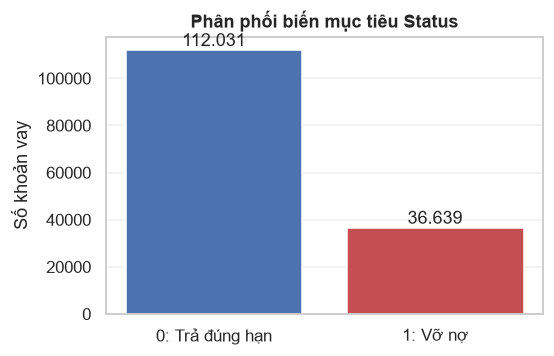

In [4]:
dist = raw[TARGET].value_counts().sort_index()
base_rate = raw[TARGET].mean()
show(pd.DataFrame({"Số khoản vay": dist}), {"Số khoản vay": 0})
print(f"\nTỷ lệ vỡ nợ nền: {vn(100 * base_rate, 2)}% "
      f"— cân bằng 1:{vn(1 / base_rate - 1, 2)}")

fig, ax = plt.subplots(figsize=(5.2, 3.4))
bars = ax.bar(["0: Trả đúng hạn", "1: Vỡ nợ"], dist.values,
              color=["#4C72B0", "#C44E52"])
ax.bar_label(bars, labels=[vn(v) for v in dist.values])
ax.set_ylabel("Số khoản vay")
ax.set_title("Phân phối biến mục tiêu Status")
ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(f"{FIGDIR}/01_target.png"); plt.show()

Tỷ lệ vỡ nợ trong tập dữ liệu là 24,6%. Nếu dự đoán toàn bộ là lớp 0 (không vỡ nợ), độ chính xác (accuracy) vẫn đạt 75,4% nhưng không mang ý nghĩa thực tế. Do đó, bài toán sử dụng ROC-AUC, PR-AUC, độ nhạy (recall) theo từng ngưỡng và biểu đồ lift/gain làm thước đo chính. Pipeline đánh giá trực tiếp trên phân phối thực tế thay vì can thiệp trọng số mẫu (`class_weight`), giúp phản ánh chính xác rủi ro khi vận hành.

## 1.4. Kiểm tra khóa chính và tính nhất quán nội tại

Bộ dữ liệu gồm một bảng đơn lẻ (`Loan_Default.csv`, 148.670 dòng × 34 cột). Các kiểm tra tính nhất quán nội tại gồm:
1. Trường `ID` đại diện cho khóa chính duy nhất với 148.670 giá trị phân biệt, trải liên tục trong khoảng từ 24.890 đến 173.559, không có bản ghi trùng lặp.
2. Công thức kế toán `LTV = loan_amount / property_value * 100` khớp trên toàn bộ các dòng có đủ dữ liệu (sai lệch tuyệt đối bằng 0).
3. Tập dữ liệu khuyết thiếu của `LTV` và `property_value` hoàn toàn trùng khớp nhau với 15.098 dòng. Trong số này, có 15.096 dòng khuyết đồng thời cả 4 trường định giá tài chính (mục 1.7).

| File | Số dòng | Số cột | Khóa | Ghi chú |
|---|---|---|---|---|
| `Loan_Default.csv` | 148.670 | 34 | `ID` (duy nhất, liên tục) | Bảng duy nhất; không có khóa ngoại |

In [5]:
print("Bản ghi lặp toàn bộ dòng :", raw.duplicated().sum())
print("ID trùng (khóa chính)     :", raw.duplicated(subset=["ID"]).sum())
print("Số ID phân biệt           :", raw["ID"].nunique(), "/", len(raw))
print("Khoảng ID                 :", raw["ID"].min(), "→", raw["ID"].max())
print("ID liên tục (không thủng) :", bool(
    (np.sort(raw["ID"].values) == np.arange(raw["ID"].min(), raw["ID"].max() + 1)).all()))

Bản ghi lặp toàn bộ dòng : 0
ID trùng (khóa chính)     : 0
Số ID phân biệt           : 148670 / 148670
Khoảng ID                 : 24890 → 173559
ID liên tục (không thủng) : True


## 1.5. Rà soát kiểu dữ liệu và miền giá trị

Kiểm tra tính hợp lệ trên các trường dữ liệu trọng yếu:
* `loan_amount`: Có kiểu số nguyên `int64`, không khuyết thiếu và chỉ có 211 giá trị phân biệt. Tất cả khoản vay đều là bội số của 500 USD, cho thấy dữ liệu đã được làm tròn thành các khoảng (bucket).
* `Credit_Score`: Nằm trọn trong khoảng hợp lệ từ 500 đến 900 điểm.
* `LTV`: Khớp với tỷ lệ `loan_amount / property_value * 100`.
* Cột `year` chỉ nhận một giá trị duy nhất (2019), không mang giá trị phân biệt.
* Các biến phân loại như `loan_limit`, `loan_purpose`, `credit_type` đang ở dạng ký hiệu viết tắt nội bộ (`cf/ncf`, `p1..p4`, `l1/l2`), cần được ánh xạ lại nhãn có nghĩa nghiệp vụ.

In [6]:
# Kiểm chứng Giả định 1 — tính "bucket" của loan_amount
print("--- Giả định 1: loan_amount ---")
print("kiểu dữ liệu:", raw["loan_amount"].dtype, "| thiếu:", int(raw["loan_amount"].isna().sum()),
      "| số giá trị phân biệt:", raw["loan_amount"].nunique())
print("miền:", raw["loan_amount"].min(), "→", raw["loan_amount"].max(),
      "| là bội số của 500:", bool((raw["loan_amount"] % 500 == 0).all()))

# Kiểm chứng Giả định 2 — miền của Credit_Score
print("\n--- Giả định 2: Credit_Score ---")
print("kiểu dữ liệu:", raw["Credit_Score"].dtype, "| miền:",
      raw["Credit_Score"].min(), "→", raw["Credit_Score"].max(),
      "| ngoài [300, 900]:", int((~raw["Credit_Score"].between(300, 900)).sum()))

# Cột số nhưng bị đọc dạng object (quét toàn bộ)
print("\n--- Giả định kiểu dữ liệu: cột object suy ra được số ---")
found = False
for c in raw.select_dtypes("object").columns:
    pct_ok = pd.to_numeric(raw[c], errors="coerce").notna().mean()
    if pct_ok > 0.9:
        print(f"{c:26s} suy ra được số: {vn(100 * pct_ok, 1)}%")
        found = True
if not found:
    print("không có cột nào bị sai kiểu (loan_amount và Credit_Score đều đã là số)")

# Kiểm chứng Giả định 3 — tính nhất quán dẫn xuất của LTV
pv = raw["property_value"].astype(float)
la = raw["loan_amount"].astype(float)
mask = pv.notna() & (pv > 0) & raw["LTV"].notna()
diff = (raw.loc[mask, "LTV"] - (la[mask] / pv[mask] * 100)).abs()
print("\n--- Giả định 3: LTV = loan_amount / property_value * 100 ---")
print(f"median|Δ| = {vn(diff.median(), 2)} | max|Δ| = {vn(diff.max(), 2)} | "
      f"tỷ lệ khớp (|Δ| < 1) = {vn(100 * (diff < 1).mean(), 2)}%")
print("Bộ khuyết thiếu của LTV trùng khớp property_value:",
      bool((raw["LTV"].isna() == raw["property_value"].isna()).all()))

# Cột hằng số và các nhãn phân loại "mã hóa mù"
print("\n--- Cột hằng số (không mang thông tin) ---")
const_cols = [c for c in raw.columns if raw[c].nunique(dropna=False) <= 1]
print(const_cols or "không có")
print("\n--- Biến phân loại còn mã code, cần ánh xạ tên diễn giải ---")
for c in ["loan_limit", "loan_purpose", "Credit_Worthiness", "open_credit",
          "construction_type", "Secured_by", "Security_Type", "Region"]:
    print(f"{c:22s}: {sorted(map(str, raw[c].dropna().unique()))}")


--- Giả định 1: loan_amount ---
kiểu dữ liệu: int64 | thiếu: 0 | số giá trị phân biệt: 211
miền: 16500 → 3576500 | là bội số của 500: True

--- Giả định 2: Credit_Score ---
kiểu dữ liệu: int64 | miền: 500 → 900 | ngoài [300, 900]: 0

--- Giả định kiểu dữ liệu: cột object suy ra được số ---


không có cột nào bị sai kiểu (loan_amount và Credit_Score đều đã là số)

--- Giả định 3: LTV = loan_amount / property_value * 100 ---
median|Δ| = 0,00 | max|Δ| = 0,00 | tỷ lệ khớp (|Δ| < 1) = 100,00%
Bộ khuyết thiếu của LTV trùng khớp property_value: True

--- Cột hằng số (không mang thông tin) ---
['year']

--- Biến phân loại còn mã code, cần ánh xạ tên diễn giải ---


loan_limit            : ['cf', 'ncf']
loan_purpose          : ['p1', 'p2', 'p3', 'p4']
Credit_Worthiness     : ['l1', 'l2']
open_credit           : ['nopc', 'opc']
construction_type     : ['mh', 'sb']
Secured_by            : ['home', 'land']
Security_Type         : ['Indriect', 'direct']
Region                : ['North', 'North-East', 'central', 'south']


## 1.6. Bảng mã hóa các trường danh mục

Bộ dữ liệu chứa 21 biến danh mục dưới dạng ký hiệu mã hóa (`cf/ncf`, `p1..p4`, `l1/l2`, `sb/mh`, `CIB/CRIF/EXP/EQUI`). Các trường được lập bản đồ chuyển đổi:
* Các ký hiệu theo quy chuẩn thị trường thế chấp Mỹ (loại hạn mức, tình trạng sở hữu, loại bất động sản bảo đảm) được giải mã theo chuẩn chung.
* Các ký hiệu mang tính nội bộ của tập dữ liệu (`loan_purpose`, `Credit_Worthiness`, `submission_of_application`) được gán nhãn trung tính kèm phân loại mức độ tin cậy của suy đoán.

In [7]:
CODEBOOK = {
    # cột: {giá trị gốc: (nhãn diễn giải, độ tin cậy)}
    "loan_limit": {"cf": ("Conforming - hạn mức chuẩn", "chuẩn ngành"),
                   "ncf": ("Non-conforming - vượt hạn chuẩn", "chuẩn ngành")},
    "approv_in_adv": {"pre": ("Được phê duyệt trước", "chuẩn ngành"),
                      "nopre": ("Không phê duyệt trước", "chuẩn ngành")},
    "loan_type": {"type1": ("Loại 1", "không rõ"), "type2": ("Loại 2", "không rõ"),
                  "type3": ("Loại 3", "không rõ")},
    "loan_purpose": {"p1": ("Mục đích 1", "suy đoán: mua nhà"),
                     "p2": ("Mục đích 2", "suy đoán: xây mới"),
                     "p3": ("Mục đích 3", "suy đoán: tái tài trợ"),
                     "p4": ("Mục đích 4", "suy đoán: đầu tư")},
    "Credit_Worthiness": {"l1": ("Hạng tín dụng L1", "suy đoán: đủ điều kiện"),
                          "l2": ("Hạng tín dụng L2", "suy đoán: dưới chuẩn")},
    "open_credit": {"opc": ("Có sẵn khoản vay mở", "chuẩn ngành"),
                    "nopc": ("Không có khoản vay mở", "chuẩn ngành")},
    "business_or_commercial": {"b/c": ("Mục đích kinh doanh/thương mại", "chuẩn ngành"),
                               "nob/c": ("Mục đích cá nhân", "chuẩn ngành")},
    "Neg_ammortization": {"neg_amm": ("Trả dần âm", "chuẩn ngành"),
                          "not_neg": ("Không trả dần âm", "chuẩn ngành")},
    "interest_only": {"int_only": ("Chỉ trả lãi", "chuẩn ngành"),
                      "not_int": ("Trả gốc + lãi", "chuẩn ngành")},
    "lump_sum_payment": {"lpsm": ("Trả một lần cuối kỳ", "chuẩn ngành"),
                         "not_lpsm": ("Trả góp đều", "chuẩn ngành")},
    "construction_type": {"sb": ("Nhà truyền thống (stick-built)", "chuẩn ngành"),
                          "mh": ("Nhà di động (manufactured)", "chuẩn ngành")},
    "occupancy_type": {"pr": ("Ở chính (primary)", "chuẩn ngành"),
                       "ir": ("Đầu tư (investment)", "chuẩn ngành"),
                       "sr": ("Thứ hai (secondary)", "chuẩn ngành")},
    "Secured_by": {"home": ("Thế chấp bằng nhà", "chuẩn ngành"),
                   "land": ("Thế chấp bằng đất", "chuẩn ngành")},
    "total_units": {"1U": ("1 căn hộ", "chuẩn ngành"), "2U": ("2 căn hộ", "chuẩn ngành"),
                    "3U": ("3 căn hộ", "chuẩn ngành"), "4U": ("4 căn hộ", "chuẩn ngành")},
    "credit_type": {"CIB": ("Bureau CIB", "không rõ"), "CRIF": ("Bureau CRIF", "không rõ"),
                    "EXP": ("Bureau EXP", "không rõ"), "EQUI": ("Bureau EQUI", "không rõ")},
    "co-applicant_credit_type": {"CIB": ("Bureau CIB", "không rõ"),
                                 "EXP": ("Bureau EXP", "không rõ")},
    "submission_of_application": {
        "to_inst": ("Nộp tới tổ chức", "suy đoán"),
        "not_inst": ("Không nộp tới tổ chức", "suy đoán")},
    "Security_Type": {"direct": ("Bảo đảm trực tiếp", "chuẩn ngành"),
                      "Indriect": ("Bảo đảm gián tiếp (spelling gốc)", "chuẩn ngành")},
    "Region": {"North": ("Miền Bắc", "chuẩn ngành"), "south": ("Miền Nam", "chuẩn ngành"),
               "central": ("Miền Trung", "chuẩn ngành"),
               "North-East": ("Đông Bắc", "chuẩn ngành")},
    "Gender": {"Male": ("Nam", "chuẩn ngành"), "Female": ("Nữ", "chuẩn ngành"),
               "Joint": ("Vay đồng sở hữu", "chuẩn ngành"),
               "Sex Not Available": ("Không công khai giới tính", "chuẩn ngành")},
}

# Kích thước từng nhóm giá trị, để thấy trường nào gần như chỉ có một nhóm
sizes = []
for col, mp in CODEBOOK.items():
    vc = raw[col].value_counts(dropna=False)
    for val, (label, trust) in mp.items():
        sizes.append({"Cột": col, "Mã": val, "Diễn giải": label, "Độ tin cậy": trust,
                      "Số dòng": int(vc.get(val, 0)),
                      "Tỷ lệ (%)": round(100 * vc.get(val, 0) / len(raw), 2)})
codebook = pd.DataFrame(sizes)
show(codebook)

# Kiểm tra: có mã nào xuất hiện trong data mà chưa được khai báo trong từ điển không?
unknown = []
for col, mp in CODEBOOK.items():
    extra = set(raw[col].dropna().unique()) - set(mp)
    if extra:
        unknown.append((col, extra))
print("Mã chưa ánh xạ:", unknown or "không có — từ điển phủ kín")

,Cột,Mã,Diễn giải,Độ tin cậy,Số dòng,Tỷ lệ (%)
0,loan_limit,cf,Conforming - hạn mức chuẩn,chuẩn ngành,135.348,"91,04"
1,loan_limit,ncf,Non-conforming - vượt hạn chuẩn,chuẩn ngành,9.978,"6,71"
2,approv_in_adv,pre,Được phê duyệt trước,chuẩn ngành,23.141,"15,57"
3,approv_in_adv,nopre,Không phê duyệt trước,chuẩn ngành,124.621,"83,82"
4,loan_type,type1,Loại 1,không rõ,113.173,"76,12"
5,loan_type,type2,Loại 2,không rõ,20.762,"13,97"
6,loan_type,type3,Loại 3,không rõ,14.735,"9,91"
7,loan_purpose,p1,Mục đích 1,suy đoán: mua nhà,34.529,"23,23"
8,loan_purpose,p2,Mục đích 2,suy đoán: xây mới,3.274,"2,20"
9,loan_purpose,p3,Mục đích 3,suy đoán: tái tài trợ,55.934,"37,62"


Mã chưa ánh xạ:

 không có — từ điển phủ kín


## 1.7. Cơ chế khuyết thiếu và nguy cơ rò rỉ dữ liệu (Data Leakage)

Tập dữ liệu có 181.135 giá trị khuyết phân bổ trên 14 cột, trung bình mỗi khoản vay thiếu 1,2 trường. Khi việc thiếu dữ liệu gắn liền với trạng thái vỡ nợ (cơ chế MNAR), cờ báo khuyết thiếu sẽ trở thành đặc trưng rò rỉ nhãn, khiến mô hình đạt điểm số cao ảo nhưng mất khả năng ứng dụng thực tế.

Phần này phân tích tương quan giữa trạng thái khuyết thiếu và tỷ lệ vỡ nợ, đồng thời đo lường mức độ đồng xuất hiện của các ô trống giữa các thuộc tính.

In [8]:
miss_cols = [c for c in raw.columns if raw[c].isna().any()]
tbl = []
for c in miss_cols:
    m = raw[c].isna()
    tbl.append({
        "Cột": c,
        "Tỷ lệ thiếu (%)": round(100 * m.mean(), 2),
        "Tỷ lệ vỡ nợ | thiếu (%)": round(100 * raw.loc[m, TARGET].mean(), 2),
        "Tỷ lệ vỡ nợ | đủ (%)": round(100 * raw.loc[~m, TARGET].mean(), 2),
        "Chênh lệch (điểm %)": round(100 * (raw.loc[m, TARGET].mean()
                                            - raw.loc[~m, TARGET].mean()), 2),
    })
miss_tbl = pd.DataFrame(tbl).sort_values("Chênh lệch (điểm %)", ascending=False)
show(miss_tbl)

# Ma trận đồng xuất hiện của các ô trống (Jaccard) để kiểm tra các trường có khuyết thiếu cùng nhau không
M = raw[miss_cols].isna().astype(np.int64)
dot = M.T.dot(M)
jac = dot / (M.sum().values[:, None] + M.sum().values - dot)
J = pd.DataFrame(jac, index=miss_cols, columns=miss_cols)

# Loại bỏ đường chéo để lọc các cặp trường thực sự đồng xuất hiện với nhau
off = J.where(~np.eye(len(J), dtype=bool))
keep_cols = off.columns[off.max(axis=0) > 0.4]
jaccard_sub = J.loc[keep_cols, keep_cols].round(3)
show(jaccard_sub, {c: 3 for c in jaccard_sub.columns})

,Cột,Tỷ lệ thiếu (%),Tỷ lệ vỡ nợ | thiếu (%),Tỷ lệ vỡ nợ | đủ (%),Chênh lệch (điểm %)
4,Interest_rate_spread,"24,64","100,00","0,00","100,00"
3,rate_of_interest,"24,51","100,00","0,18","99,82"
5,Upfront_charges,"26,66","92,04","0,14","91,90"
8,property_value,"10,16","99,99","16,13","83,86"
12,LTV,"10,16","99,99","16,13","83,86"
10,age,"0,13","100,00","24,54","75,46"
11,submission_of_application,"0,13","100,00","24,54","75,46"
13,dtir1,"16,22","67,62","16,32","51,30"
6,term,"0,03","36,59","24,64","11,94"
1,approv_in_adv,"0,61","26,54","24,63","1,91"


,rate_of_interest,Interest_rate_spread,Upfront_charges,property_value,age,submission_of_application,LTV,dtir1
rate_of_interest,"1,000","0,995","0,919","0,414","0,000","0,000","0,414","0,362"
Interest_rate_spread,"0,995","1,000","0,917","0,412","0,005","0,005","0,412","0,367"
Upfront_charges,"0,919","0,917","1,000","0,381","0,001","0,001","0,381","0,350"
property_value,"0,414","0,412","0,381","1,000","0,000","0,000","1,000","0,626"
age,"0,000","0,005","0,001","0,000","1,000","1,000","0,000","0,008"
submission_of_application,"0,000","0,005","0,001","0,000","1,000","1,000","0,000","0,008"
LTV,"0,414","0,412","0,381","1,000","0,000","0,000","1,000","0,626"
dtir1,"0,362","0,367","0,350","0,626","0,008","0,008","0,626","1,000"


## 1.8. Định lượng cụm khuyết thiếu theo nhãn

Bốn trường gồm `rate_of_interest`, `Interest_rate_spread`, `Upfront_charges` và `property_value`/`LTV` có tần suất khuyết thiếu đồng thời rất cao. Mức độ tập trung của cụm khuyết này đối với nhãn `Status` được đo lường cụ thể làm căn cứ xây dựng mô hình.

Cụm 4 trường cùng trống : 15.096 dòng (10,15% dữ liệu)
Tỷ lệ vỡ nợ trong cụm   : 100,00%
Chiếm 41,20% tổng số ca vỡ nợ (15.096/36.639)
Vỡ nợ NGOÀI cụm         : 16,13%

credit_type == EQUI     : 15.298 dòng, tỷ lệ vỡ nợ 99,99%
EQUI giao cụm trống     : 15.096 dòng | EQUI ngoài cụm: 202 | cụm ngoài EQUI: 0
P(vỡ nợ | EQUI) = 0,9999 | P(EQUI | vỡ nợ) = 0,4175

Kiểm định χ² (nhãn × cụm 4 trường trống): χ² = 51.371,2 | bậc tự do = 1 | p < 0,0001


Status,Trả đủ,Vỡ nợ
cụm 4 trường trống,,
False,"83,87","16,13"
True,"0,00","100,00"



Kiểm định χ² (nhãn × credit_type=EQUI): χ² = 52.128,5 | bậc tự do = 1 | p < 0,0001


Status,Trả đủ,Vỡ nợ
credit_type=EQUI,,
False,"84,00","16,00"
True,"0,01","99,99"



--- Giá trị sentinel trùng nhãn ---


,Số dòng,% dữ liệu,Tỷ lệ vỡ nợ trong nhóm (%)
Interest_rate_spread trống,36.639,"24,64","100,00"
age trống,200,"0,13","100,00"
rate_of_interest trống,36.439,"24,51","100,00"
property_value/LTV trống,15.098,"10,16","99,99"
income == 0,1.260,"0,85","99,37"
dtir1 trống,24.121,"16,22","67,62"
Upfront_charges == 0,20.770,"13,97","0,26"


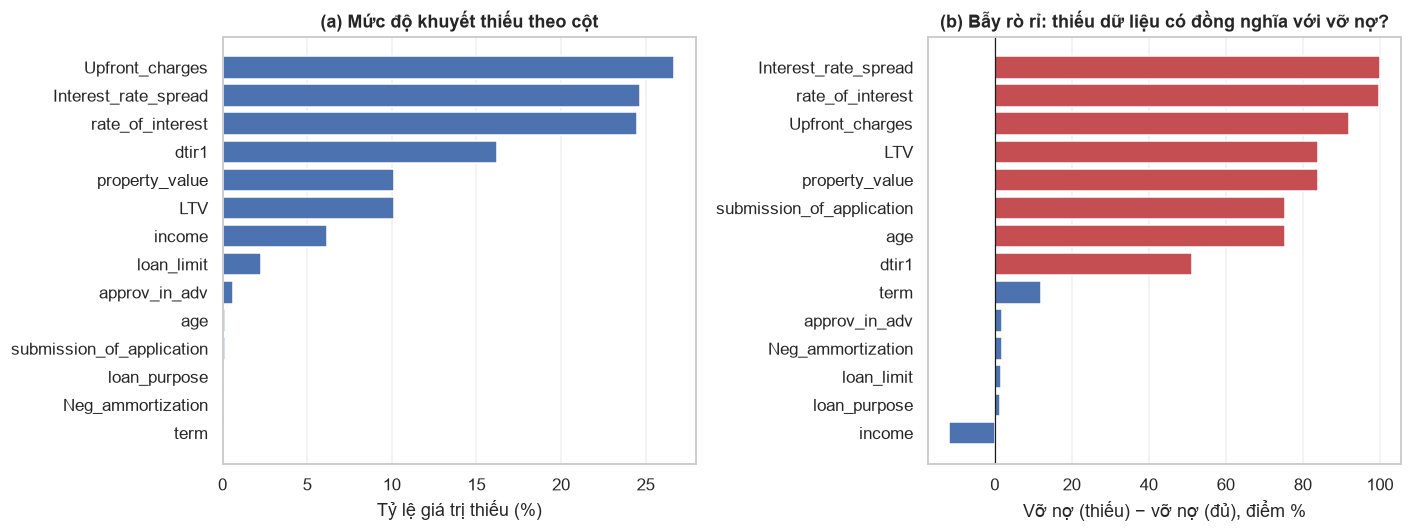

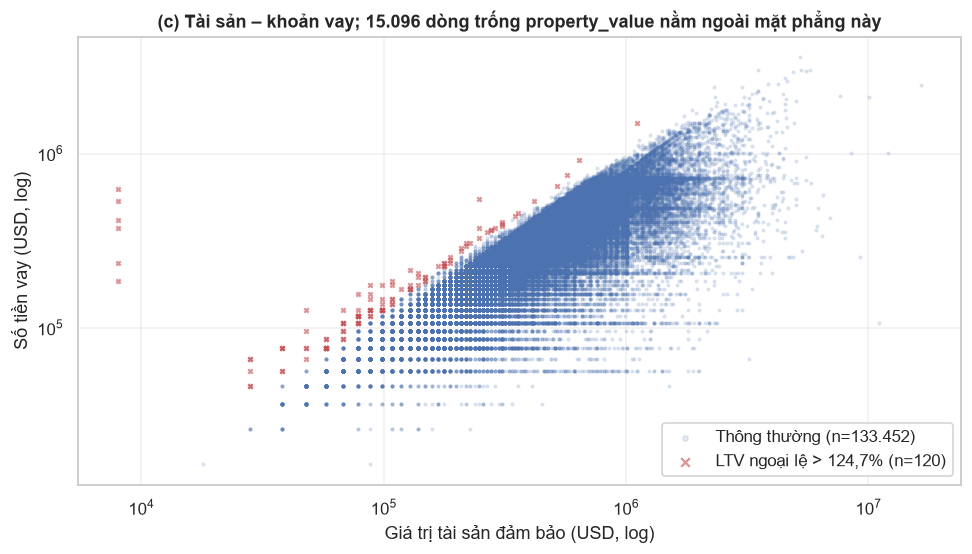

In [9]:
null_cluster = (raw["rate_of_interest"].isna() & raw["Interest_rate_spread"].isna()
                & raw["Upfront_charges"].isna() & raw["property_value"].isna())
n_cl = int(null_cluster.sum())
print(f"Cụm 4 trường cùng trống : {vn(n_cl)} dòng ({vn(100*n_cl/len(raw), 2)}% dữ liệu)")
print(f"Tỷ lệ vỡ nợ trong cụm   : {vn(100*raw.loc[null_cluster, TARGET].mean(), 2)}%")
print(f"Chiếm {vn(100*null_cluster[raw[TARGET]==1].mean(), 2)}% tổng số ca vỡ nợ",
      f"({vn(int(null_cluster[raw[TARGET]==1].sum()))}/{vn(int(raw[TARGET].sum()))})")
print(f"Vỡ nợ NGOÀI cụm         : {vn(100*raw.loc[~null_cluster, TARGET].mean(), 2)}%")

# Trường phân loại gần như tương đương 1-1 với cụm trống → chính là "kênh rò rỉ"
eq = raw["credit_type"].eq("EQUI")
n_eq, n_both = int(eq.sum()), int((eq & null_cluster).sum())
print(f"\ncredit_type == EQUI     : {vn(n_eq)} dòng, tỷ lệ vỡ nợ {vn(100*raw.loc[eq, TARGET].mean(), 2)}%")
print(f"EQUI giao cụm trống     : {vn(n_both)} dòng | EQUI ngoài cụm: "
      f"{vn(n_eq - n_both)} | cụm ngoài EQUI: {vn(n_cl - n_both)}")
print(f"P(vỡ nợ | EQUI) = {vn(raw.loc[eq, TARGET].mean(), 4)} | "
      f"P(EQUI | vỡ nợ) = {vn(eq[raw[TARGET]==1].mean(), 4)}")

# Kiểm định χ² về tính độc lập giữa "bị thiếu dữ liệu" và nhãn
for name, mask in [("cụm 4 trường trống", null_cluster), ("credit_type=EQUI", eq)]:
    ct = pd.crosstab(mask, raw[TARGET])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    ct.index.name = name
    print(f"\nKiểm định χ² (nhãn × {name}): χ² = {vn(chi2, 1)} | bậc tự do = {dof} | {pstr(p)}")
    show((100 * ct / ct.sum(axis=1).values[:, None]).round(2)
         .rename(columns={0: "Trả đủ", 1: "Vỡ nợ"}))

# Các "kênh rò rỉ" dạng giá trị đặc biệt (sentinel) khác
print("\n--- Giá trị sentinel trùng nhãn ---")
sentinels = {
    "income == 0": raw["income"].eq(0),
    "Upfront_charges == 0": raw["Upfront_charges"].eq(0),
    "Interest_rate_spread trống": raw["Interest_rate_spread"].isna(),
    "rate_of_interest trống": raw["rate_of_interest"].isna(),
    "property_value/LTV trống": raw["property_value"].isna(),
    "dtir1 trống": raw["dtir1"].isna(),
    "age trống": raw["age"].isna(),
}
sent = pd.DataFrame({
    "Số dòng": {k: int(v.sum()) for k, v in sentinels.items()},
    "% dữ liệu": {k: round(100 * v.mean(), 2) for k, v in sentinels.items()},
    "Tỷ lệ vỡ nợ trong nhóm (%)": {k: round(100 * raw.loc[v, TARGET].mean(), 2)
                             for k, v in sentinels.items()},
})
show(sent.sort_values("Tỷ lệ vỡ nợ trong nhóm (%)", ascending=False))

# Vẽ: mức độ thiếu và bẫy rò rỉ của từng cột
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
mc = miss_tbl.sort_values("Tỷ lệ thiếu (%)")
axes[0].barh(mc["Cột"], mc["Tỷ lệ thiếu (%)"], color="#4C72B0")
axes[0].set_xlabel("Tỷ lệ giá trị thiếu (%)")
axes[0].set_title("(a) Mức độ khuyết thiếu theo cột")
axes[0].grid(axis="y", visible=False)
mv = miss_tbl.sort_values("Chênh lệch (điểm %)")
axes[1].barh(mv["Cột"], mv["Chênh lệch (điểm %)"],
             color=np.where(mv["Chênh lệch (điểm %)"] > 30, "#C44E52", "#4C72B0"))
axes[1].axvline(0, color="k", lw=.8)
axes[1].set_xlabel("Vỡ nợ (thiếu) − vỡ nợ (đủ), điểm %")
axes[1].set_title("(b) Bẫy rò rỉ: thiếu dữ liệu có đồng nghĩa với vỡ nợ?")
axes[1].grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(f"{FIGDIR}/02_missing.png"); plt.show()

# Scatter property_value × loan_amount minh hoạ miền ngoại lệ LTV
fig, ax = plt.subplots(figsize=(9, 5.2))
sub = raw[raw["property_value"].notna() & raw["LTV"].notna()]
q1, q3 = sub["LTV"].quantile([.25, .75])
ltv_hi = q3 + IQR_K * (q3 - q1)
big = sub["LTV"] > ltv_hi
ax.scatter(sub.loc[~big, "property_value"], sub.loc[~big, "loan_amount"],
           s=3, alpha=.15, color="#4C72B0",
           label=f"Thông thường (n={vn(int((~big).sum()))})")
ax.scatter(sub.loc[big, "property_value"], sub.loc[big, "loan_amount"],
           s=8, alpha=.6, marker="x", color="#C44E52",
           label=f"LTV ngoại lệ > {vn(ltv_hi, 1)}% (n={vn(int(big.sum()))})")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Giá trị tài sản đảm bảo (USD, log)")
ax.set_ylabel("Số tiền vay (USD, log)")
ax.set_title(f"(c) Tài sản – khoản vay; {vn(n_cl)} dòng trống property_value "
             "nằm ngoài mặt phẳng này")
ax.legend(loc="lower right", framealpha=.9, markerscale=2)
fig.tight_layout(); fig.savefig(f"{FIGDIR}/03_pv_vs_loan.png"); plt.show()


### Nhận định về cơ chế rò rỉ dữ liệu

Kết quả kiểm định cho thấy tình trạng thiếu dữ liệu phản ánh trực tiếp trạng thái vỡ nợ:

1. **Cụm 4 trường định giá:** Hồ sơ khuyết đồng thời `rate_of_interest`, `Interest_rate_spread`, `Upfront_charges` và `property_value`/`LTV` có tỷ lệ vỡ nợ là 100%, chiếm hơn 40% tổng số ca vỡ nợ trong toàn bộ dữ liệu. Kiểm định Chi-square bác bỏ giả thuyết độc lập giữa tình trạng thiếu dữ liệu và nhãn mục tiêu.
2. **Các kênh rò rỉ khác:** Giá trị `credit_type = EQUI` tương đương với cụm khuyết dữ liệu. Tương tự, `income = 0` và giá trị rỗng ở `Interest_rate_spread` đều gắn với các ca vỡ nợ với xác suất gần như tuyệt đối.
3. **Tác động đến mô hình:** Nếu tiếp tục sử dụng các cột này kèm cờ thiếu, mô hình sẽ đạt ROC-AUC rất cao do nhận diện được quy trình lưu trữ hồ sơ thay vì học được rủi ro tín dụng của khách hàng.

**Quyết định xử lý:** Tập dữ liệu dùng để huấn luyện mô hình chuẩn (`X_clean`) sẽ loại bỏ hoàn toàn các trường và cờ rò rỉ này.

# Phần 2. Tiền xử lý và làm sạch dữ liệu

## 2.1. Phân loại dị biệt và kiểm tra tính khả thi của dữ liệu

Các nhóm dữ liệu bất thường được phân loại để áp dụng phương pháp xử lý thích hợp: tạo cờ định danh, xử lý giá trị cực đoan bằng phân vị (winsorization), chuyển đổi giá trị mã kỹ thuật (sentinel) về `NaN`, và giữ lại các phân khúc sản phẩm đặc thù.

Bên cạnh đó, cần kiểm tra xem sau khi loại bỏ các yếu tố rò rỉ, tập dữ liệu còn đủ biến thiên của nhãn mục tiêu để xây dựng mô hình dự báo hay không.

| Mã | Dị biệt | Hiện trạng kiểm chứng | Phương án xử lý | Cơ sở lựa chọn |
|---|---|---|---|---|
| L1 | `Interest_rate_spread` trống | 36.639 dòng trống bằng đúng số ca vỡ nợ; AUC cờ thiếu = 1,0000 | Loại bỏ cột | Tránh đưa thông tin tương đương nhãn vào mô hình |
| L2 | `rate_of_interest` trống | Tỷ lệ vỡ nợ khi trống là 100,00%; chiếm 99,45% số ca vỡ nợ | Đánh dấu phân khúc A bằng cờ thiếu; loại bỏ khỏi tập đặc trưng sạch | Điền giá trị trung vị sẽ tạo dữ liệu giả lập cho 24,5% mẫu |
| L3 | Khuyết đồng thời 4 trường tài chính | 15.096 dòng, tỷ lệ vỡ nợ 100%, Chi-square = 51.371 | Nằm trong phân khúc A | Mã hóa one-hot vẫn để lộ tín hiệu rò rỉ |
| L4 | `credit_type = EQUI` | 15.298 dòng, tỷ lệ vỡ nợ 99,99%, Cramér's V = 0,5921 | Loại bỏ khỏi tập đặc trưng sạch | Là biến phân loại mang thông tin tương đương nhãn |
| L5 | `age` và `submission_of_application` trống | 200 dòng, tỷ lệ vỡ nợ 100% | Nhận diện trong phân khúc rò rỉ B | Khép kín các ca vỡ nợ còn lại có lãi suất |
| S1 | `income = 0` | 1.260 dòng, tỷ lệ vỡ nợ 99,37% | Chuyển về NaN | Tránh để mô hình dùng giá trị 0 làm đại diện cho nhãn |
| S2 | `Upfront_charges = 0` | 20.770 dòng, tỷ lệ vỡ nợ 0,255% | Giữ lại, tạo cờ `no_upfront_fee` | Đại diện cho gói sản phẩm miễn phí trả trước |
| O1 | `property_value` tối đa 16,5 triệu USD | Phân phối lệch phải, nhiều ngoại lệ IQR | Winsorize P1-P99 | Bảo toàn cỡ mẫu thay vì cắt bỏ dòng |
| O2 | `LTV` tối đa 7.831,25% | Đuôi phân phối dài, LTV > 100% phản ánh giá trị khoản vay vượt tài sản | Winsorize P1-P99 kèm cờ `ltv_above_100` | Giữ lại thông tin về nhóm khách hàng vay vượt giá trị tài sản |
| C1 | Cột `year` hằng số, `ID` định danh | Giá trị đơn nhất hoặc mã định danh liên tục | Loại bỏ cột | Không mang thông tin dự báo |

In [10]:
LEAK_SPREAD = raw["Interest_rate_spread"].isna()
ROI_MISSING = raw["rate_of_interest"].isna()
NULL_CLUSTER = (ROI_MISSING & LEAK_SPREAD & raw["Upfront_charges"].isna()
                & raw["property_value"].isna())
EQ_OUT = raw["credit_type"].eq("EQUI") & ~NULL_CLUSTER
AGE_NULL = raw["age"].isna()
LEAK_MASK = ROI_MISSING | EQ_OUT | AGE_NULL

ROI_ONLY = ROI_MISSING & ~NULL_CLUSTER & ~EQ_OUT
AGE_OUT = AGE_NULL & ~NULL_CLUSTER & ~EQ_OUT  # kiểm tra tuổi trống ngoài nhóm A và B
groups = pd.DataFrame({
    "Nhóm bất thường": [
        "A — cụm 4 trường cùng trống (rò rỉ tất định)",
        "B — credit_type = EQUI ngoài cụm trống",
        "C — age trống ngoài A/B/E",
        "D — còn lại (nhóm sạch)",
        "E — ROI trống nhưng tài sản quan sát được",
        "Tổng"],
    "Số dòng": [int(NULL_CLUSTER.sum()), int(EQ_OUT.sum()),
               int(AGE_OUT.sum()), int((~LEAK_MASK).sum()),
               int(ROI_ONLY.sum()), int(len(raw))],
    "Tỷ lệ vỡ nợ (%)": [round(100 * raw.loc[NULL_CLUSTER, TARGET].mean(), 2),
                  round(100 * raw.loc[EQ_OUT, TARGET].mean(), 2),
                  round(100 * raw.loc[AGE_OUT, TARGET].mean(), 2) if AGE_OUT.sum() > 0 else np.nan,
                  round(100 * raw.loc[~LEAK_MASK, TARGET].mean(), 2),
                  round(100 * raw.loc[ROI_ONLY, TARGET].mean(), 2),
                  round(100 * raw[TARGET].mean(), 2)],
})
show(groups, {"Số dòng": 0, "Tỷ lệ vỡ nợ (%)": 2})

# --- PHÉP THỬ QUYẾT ĐỊNH: nhãn còn biến thiên sau khi loại rò rỉ hay không? ---
from sklearn.metrics import roc_auc_score
print("=" * 74)
print("KIỂM CHỨNG 1 — hai kênh rò rỉ tất định:")
print(f"  [Interest_rate_spread] số ô trống = {vn(int(LEAK_SPREAD.sum()))} | "
      f"số ca vỡ nợ = {vn(int(raw[TARGET].sum()))} | "
      f"AUC(cờ thiếu → Status) = {vn(roc_auc_score(raw[TARGET], LEAK_SPREAD.astype(int)), 4)}")
print("  → Hai con số bằng nhau khít tuyệt đối: thiếu spread ⇔ vỡ nợ (1-1).")
print(f"  [rate_of_interest]     P(vỡ nợ | trống) = "
      f"{vn(100 * raw.loc[ROI_MISSING, TARGET].mean(), 2)}%  [n = {vn(int(ROI_MISSING.sum()))}]")
print(f"                         P(trống | vỡ nợ) = "
      f"{vn(100 * ROI_MISSING[raw[TARGET] == 1].mean(), 2)}%  → còn 200 ca vỡ nợ có lãi suất")
print(f"                         AUC(cờ thiếu → Status) = "
      f"{vn(roc_auc_score(raw[TARGET], ROI_MISSING.astype(int)), 4)}")

print("\nKIỂM CHỨNG 2 — 200 ca vỡ nợ 'thoát' được nằm ở đâu?")
esc = raw[~ROI_MISSING & (raw[TARGET] == 1)]
print(f"  credit_type = EQUI : {int(esc['credit_type'].eq('EQUI').sum())}/200")
print(f"  age trống          : {int(esc['age'].isna().sum())}/200")
print(f"  submission trống   : {int(esc['submission_of_application'].isna().sum())}/200")
print("  → ba cờ trùng khít nhau: nhóm này bị chính quy trình thu thập bỏ trắng hồ sơ.")

print("\nKIỂM CHỨNG 3 — sức mạnh dự đoán của cờ rò rỉ gộp ba nguồn:")
print(f"  AUC(LEAK_MASK → Status) = "
      f"{vn(roc_auc_score(raw[TARGET], LEAK_MASK.astype(int)), 4)}   "
      f"[nhóm rò rỉ = {vn(int(LEAK_MASK.sum()))} dòng]")

print("\nKIỂM CHỨNG 4 — số ca vỡ nợ còn sống sau khi loại rò rỉ:")
survivor = raw[~LEAK_MASK]
pos_cnt = int(survivor[TARGET].sum())
print(f"  tập còn lại {vn(len(survivor))} dòng, chứa {pos_cnt} ca vỡ nợ "
      f"(tỷ lệ vỡ nợ nhóm sạch = {vn(100 * survivor[TARGET].mean(), 2)}%).")
if pos_cnt == 0:
    print(f"  ⇒ TẬP CON NÀY KHÔNG CÒN CA VỠ NỢ NÀO ({pos_cnt} positive):\n"
          f"    nhãn được mã hoá ngay trong cơ chế khuyết thiếu của quy trình thu thập.")
else:
    print(f"  ⇒ TẬP CON NÀY CÒN {pos_cnt} CA VỠ NỢ.")
print("=" * 74)

full = raw.copy()   # Full view: giữ nguyên 148.670 dòng để làm sạch & định lượng rò rỉ
full["leak_flag"] = LEAK_MASK.astype(int)

,Nhóm bất thường,Số dòng,Tỷ lệ vỡ nợ (%)
0,A — cụm 4 trường cùng trống (rò rỉ tất định),15.096,"100,00"
1,B — credit_type = EQUI ngoài cụm trống,202,"99,50"
2,C — age trống ngoài A/B/E,0,
3,D — còn lại (nhóm sạch),112.030,"0,00"
4,E — ROI trống nhưng tài sản quan sát được,21.342,"100,00"
5,Tổng,148.670,"24,64"


KIỂM CHỨNG 1 — hai kênh rò rỉ tất định:
  [Interest_rate_spread] số ô trống = 36.639 | số ca vỡ nợ = 36.639 | AUC(cờ thiếu → Status) = 1,0000
  → Hai con số bằng nhau khít tuyệt đối: thiếu spread ⇔ vỡ nợ (1-1).
  [rate_of_interest]     P(vỡ nợ | trống) = 100,00%  [n = 36.439]
                         P(trống | vỡ nợ) = 99,45%  → còn 200 ca vỡ nợ có lãi suất
                         AUC(cờ thiếu → Status) = 0,9973

KIỂM CHỨNG 2 — 200 ca vỡ nợ 'thoát' được nằm ở đâu?
  credit_type = EQUI : 200/200
  age trống          : 200/200
  submission trống   : 200/200
  → ba cờ trùng khít nhau: nhóm này bị chính quy trình thu thập bỏ trắng hồ sơ.

KIỂM CHỨNG 3 — sức mạnh dự đoán của cờ rò rỉ gộp ba nguồn:
  AUC(LEAK_MASK → Status) = 1,0000   [nhóm rò rỉ = 36.640 dòng]

KIỂM CHỨNG 4 — số ca vỡ nợ còn sống sau khi loại rò rỉ:


  tập còn lại 112.030 dòng, chứa 0 ca vỡ nợ (tỷ lệ vỡ nợ nhóm sạch = 0,00%).
  ⇒ TẬP CON NÀY KHÔNG CÒN CA VỠ NỢ NÀO (0 positive):
    nhãn được mã hoá ngay trong cơ chế khuyết thiếu của quy trình thu thập.


### Mối liên hệ giữa nhãn mục tiêu và cơ chế ghi nhận dữ liệu

Số liệu thực nghiệm cho thấy tình trạng thiếu thông tin phản ánh gần như trọn vẹn trạng thái vỡ nợ:
* `Interest_rate_spread` khuyết đúng 36.639 dòng, tương ứng toàn bộ 36.639 ca vỡ nợ (AUC của cờ thiếu đạt 1,0000).
* `rate_of_interest` khuyết ở 99,45% các ca vỡ nợ.
* 200 ca vỡ nợ còn lại có lãi suất thì đều bị khuyết ở hai trường `age` và `submission_of_application`.

Từ đặc điểm này, quá trình phân tích ghi nhận các điểm sau:
1. **Phân phối của tập dữ liệu:** Khi loại bỏ các dòng mang dấu hiệu khuyết thiếu nêu trên, phân khúc D gồm 112.030 hồ sơ đều có nhãn trả nợ đúng hạn. Duy nhất 1 hồ sơ tốt còn lại trong toàn bộ 112.031 hồ sơ không vỡ nợ nằm trong nhóm B do mang mã `credit_type = EQUI`. Do đó, không thể tách ra một tập con vừa không mang dấu hiệu rò rỉ vừa có đủ cả hai nhãn.
2. **Đặc tính của mô hình:** Mô hình xây dựng trên tập đặc trưng sạch (`X_clean`) giữ nguyên số dòng và chỉ loại bỏ cột rò rỉ. Điểm số AUC ~0,74 phản ánh mức độ phân tách giữa nhóm rò rỉ và nhóm D hơn là phản ánh quan hệ hành vi tín dụng (mục 4.2).
3. **Ý nghĩa của các so sánh thống kê:** Toàn bộ 36.639 ca vỡ nợ đều nằm trong các phân khúc A, B và E. Các phân tích tương quan ở Phần 3 mang tính chất mô tả phân phối có điều kiện của mẫu dữ liệu hiện có.

## 2.2. Xác định giá trị ngoại lệ và kiểm định phân phối

Sự hiện diện của giá trị ngoại lệ được đánh giá qua ba tiêu chí:
1. Quy tắc IQR của Tukey: Xác định các điểm nằm ngoài khoảng $[Q1 - 1,5 \cdot IQR;\; Q3 + 1,5 \cdot IQR]$.
2. Hệ số bất đối xứng (skewness): Đánh giá mức độ kéo dài của đuôi phân phối.
3. Kiểm định Levene và Mann-Whitney: Kiểm tra sự khác biệt về vị trí trung tâm và phương sai giữa hai nhóm vỡ nợ và không vỡ nợ.

Lưu ý về một số trường dữ liệu:
* `loan_amount` chỉ nhận 211 giá trị phân biệt (bội số của 500 USD), do đó các ngưỡng IQR phản ánh sự phân bố theo bucket.
* `age` là biến dạng khoảng, được tính giá trị trung tâm (midpoint) để phân tích ở mục 2.6.
* `rate_of_interest` bị khuyết gần như toàn bộ ở nhóm vỡ nợ, nên thống kê phân phối chỉ đại diện cho các hồ sơ đã có thông tin lãi suất.

In [11]:
def iqr_bounds(s: pd.Series, k: float = IQR_K):
    """Trả về (Q1, Q3, IQR, cận trên, cận dưới) theo quy tắc Tukey k*IQR."""
    q1, q3 = s.quantile(.25), s.quantile(.75)
    iqr = q3 - q1
    return q1, q3, iqr, q3 + k * iqr, q1 - k * iqr


from scipy import stats

NUM_CANDIDATES = ["loan_amount", "property_value", "LTV", "income",
                  "Upfront_charges", "dtir1", "Credit_Score", "term",
                  "rate_of_interest"]

# --- Bảng chứng minh 1: ngoại lệ IQR + độ lệch đuôi trên toàn mẫu ---
rows = []
for c in NUM_CANDIDATES:
    s = full[c].dropna()
    q1, q3, iqr, hi, lo = iqr_bounds(s)
    out_hi, out_lo = int((s > hi).sum()), int((s < lo).sum())
    rows.append({
        "Trường": c,
        "Số quan sát": int(len(s)),
        "Tỷ lệ khuyết (%)": round(100 * full[c].isna().mean(), 2),
        "Q1": round(float(q1), 2),
        "Q3": round(float(q3), 2),
        "Cận trên IQR": round(float(hi), 2),
        "Max thực tế": round(float(s.max()), 2),
        "Ngoại lệ trên": out_hi,
        "Ngoại lệ dưới": out_lo,
        "Tỷ lệ ngoại lệ (%)": round(100 * (out_hi + out_lo) / len(s), 2),
        "Độ bất đối xứng": round(float(stats.skew(s)), 2),
    })
outl = pd.DataFrame(rows)
show(outl)

# --- Bảng chứng minh 2: ngoại lệ tập trung theo nhãn (Levene + Mann-Whitney) ---
cmp_rows = []
for c in NUM_CANDIDATES:
    a = full.loc[full[TARGET] == 1, c].dropna()
    b = full.loc[full[TARGET] == 0, c].dropna()
    if min(len(a), len(b)) < 30:      # nhóm quá nhỏ: không đủ căn cứ kiểm định
        continue
    lev = stats.levene(a, b, center="mean")
    mw = stats.mannwhitneyu(a, b, alternative="two-sided")
    cmp_rows.append({
        "Trường": c,
        "Trung vị vỡ nợ": round(float(a.median()), 2),
        "Trung vị trả nợ": round(float(b.median()), 2),
        "Tỷ lệ trung vị": round(float(a.median() / b.median()), 3),
        "IQR vỡ nợ": round(float(a.quantile(.75) - a.quantile(.25)), 2),
        "IQR trả nợ": round(float(b.quantile(.75) - b.quantile(.25)), 2),
        "p Levene": float(f"{lev.pvalue:.3g}"),
        "p Mann-Whitney": float(f"{mw.pvalue:.3g}"),
        "Kết luận α=0,05": ("khác phương sai" if lev.pvalue < .05 else "đồng phương sai")
                            + " / " + ("khác vị trí" if mw.pvalue < .05 else "đồng vị trí"),
    })
disp = pd.DataFrame(cmp_rows)
_disp = disp.copy()
_disp["p Levene"] = _disp["p Levene"].map(pval)
_disp["p Mann-Whitney"] = _disp["p Mann-Whitney"].map(pval)
show(_disp)

n_lev = int((disp["p Levene"] < .05).sum())
n_mw = int((disp["p Mann-Whitney"] < .05).sum())
print(f"Trong {len(disp)} trường đủ căn cứ kiểm định: {n_lev} trường bác giả thuyết "
      f"đồng phương sai (Levene) và {n_mw} trường bác giả thuyết đồng vị trí (Mann-Whitney).")
print("→ Đọc kèm cột 'Kết luận α=0,05': ở những trường đuôi nặng (property_value, LTV, income,")
print("   Upfront_charges, dtir1), ngoại lệ gắn với cơ chế sinh nhãn chứ không phân tán")
print("   ngẫu nhiên. Đây là căn cứ để winsorize (giữ dòng, nén đuôi) thay vì cắt dòng.")

,Trường,Số quan sát,Tỷ lệ khuyết (%),Q1,Q3,Cận trên IQR,Max thực tế,Ngoại lệ trên,Ngoại lệ dưới,Tỷ lệ ngoại lệ (%),Độ bất đối xứng
0,loan_amount,148.670,"0,00","196.500,00","436.500,00","796.500,00","3.576.500,00",1.895,0,"1,27","1,67"
1,property_value,133.572,"10,16","268.000,00","628.000,00","1.168.000,00","16.508.000,00",5.266,0,"3,94","4,59"
2,LTV,133.572,"10,16","60,47","86,18","124,75","7.831,25",120,1.762,"1,41","120,61"
3,income,139.520,"6,15","3.720,00","8.520,00","15.720,00","578.580,00",6.546,0,"4,69","17,31"
4,Upfront_charges,109.028,"26,66","581,49","4.812,50","11.159,01","60.000,00",2.880,0,"2,64","1,75"
5,dtir1,124.549,"16,22","31,00","45,00","66,00","61,00",0,2.013,"1,62","-0,55"
6,Credit_Score,148.670,"0,00","599,00","800,00","1.101,50","900,00",0,0,"0,00","0,00"
7,term,148.629,"0,03","360,00","360,00","360,00","360,00",0,26.944,"18,13","-2,17"
8,rate_of_interest,112.231,"24,51","3,62","4,38","5,50","8,00",846,10,"0,76","0,39"


,Trường,Trung vị vỡ nợ,Trung vị trả nợ,Tỷ lệ trung vị,IQR vỡ nợ,IQR trả nợ,p Levene,p Mann-Whitney,"Kết luận α=0,05"
0,loan_amount,"276.500,00","306.500,00","0,90","240.000,00","240.000,00","< 0,0001","< 0,0001",khác phương sai / khác vị trí
1,property_value,"348.000,00","428.000,00","0,81","330.000,00","350.000,00","< 0,0001","< 0,0001",khác phương sai / khác vị trí
2,LTV,"79,36","74,50","1,06","26,68","25,23","< 0,0001","< 0,0001",khác phương sai / khác vị trí
3,income,"4.860,00","6.000,00","0,81","4.620,00","4.740,00","< 0,0001","< 0,0001",khác phương sai / khác vị trí
4,Upfront_charges,"687,85","2.600,00","0,27","2.310,75","4.230,93","< 0,0001","< 0,0001",khác phương sai / khác vị trí
5,dtir1,"42,00","38,00","1,10","17,00","13,00","< 0,0001","< 0,0001",khác phương sai / khác vị trí
6,Credit_Score,"700,00","699,00","1,00","203,50","201,00","0,0059","0,1240",khác phương sai / đồng vị trí
7,term,"360,00","360,00","1,00","0,00","0,00","0,0003","< 0,0001",khác phương sai / khác vị trí
8,rate_of_interest,"4,31","3,99","1,08","0,76","0,75","0,2100","< 0,0001",đồng phương sai / khác vị trí


Trong 9 trường đủ căn cứ kiểm định: 8 trường bác giả thuyết đồng phương sai (Levene) và 8 trường bác giả thuyết đồng vị trí (Mann-Whitney).
→ Đọc kèm cột 'Kết luận α=0,05': ở những trường đuôi nặng (property_value, LTV, income,
   Upfront_charges, dtir1), ngoại lệ gắn với cơ chế sinh nhãn chứ không phân tán
   ngẫu nhiên. Đây là căn cứ để winsorize (giữ dòng, nén đuôi) thay vì cắt dòng.


## 2.3. Phân phối đuôi nặng và cấu trúc khuyết thiếu

Mục này trực quan hóa ba đặc tính phân phối của dữ liệu:
1. Biểu đồ hộp trên thang đo logarit nhằm quan sát mức độ kéo dài của các giá trị ngoại lệ.
2. Tương quan giữa giá trị khoản vay và giá trị tài sản bảo đảm nhằm giải thích nguồn gốc các trường hợp `LTV` cao.
3. Bản đồ nhiệt về tần suất đồng khuyết thiếu giữa các cột dữ liệu (minh họa cho cơ chế rò rỉ ở mục 2.1).

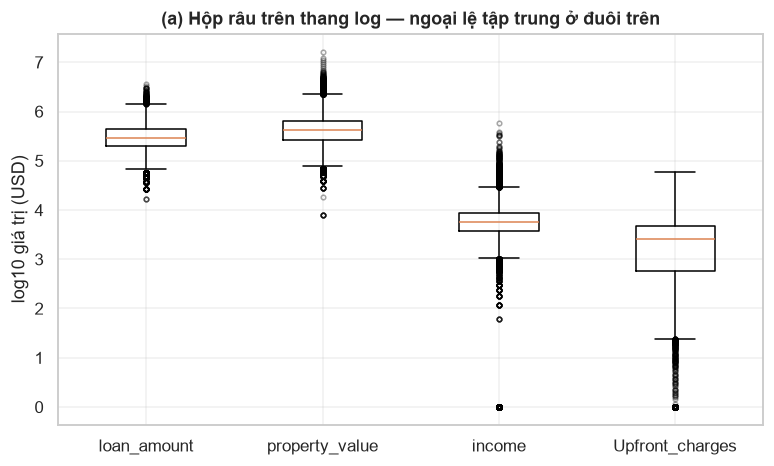

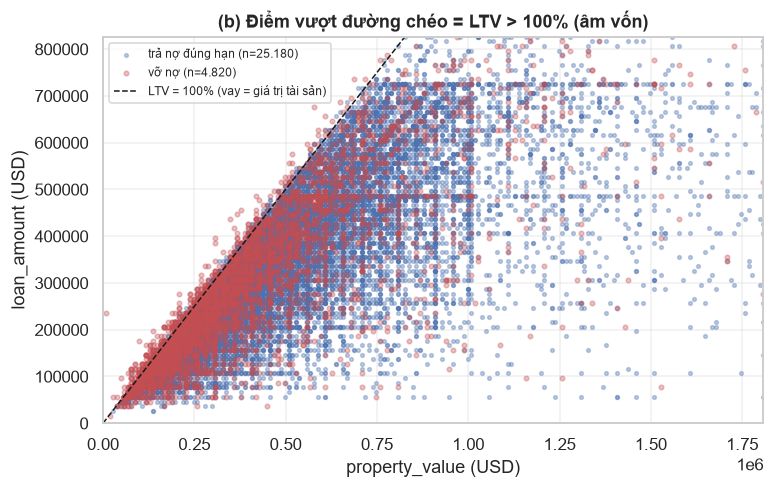

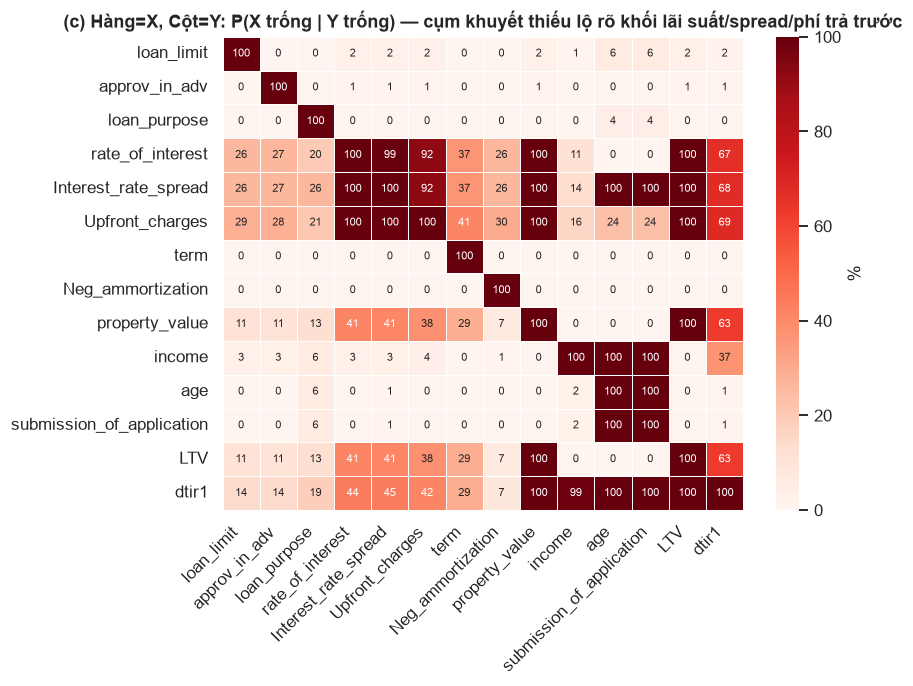

,rate_of_interest,Interest_rate_spread,Upfront_charges,property_value,LTV,dtir1,income,age
rate_of_interest,"100,00","99,50","91,90","100,00","100,00","66,80","11,40","0,00"
Interest_rate_spread,"100,00","100,00","92,00","100,00","100,00","67,60","13,50","100,00"
Upfront_charges,"100,00","99,60","100,00","100,00","100,00","68,50","15,90","23,50"
property_value,"41,40","41,20","38,10","100,00","100,00","62,60","0,20","0,00"
LTV,"41,40","41,20","38,10","100,00","100,00","62,60","0,20","0,00"
dtir1,"44,20","44,50","41,70","100,00","100,00","100,00","98,80","100,00"
income,"2,90","3,40","3,70","0,10","0,10","37,50","100,00","100,00"
age,"0,00","0,50","0,10","0,00","0,00","0,80","2,20","100,00"


In [12]:
money = ["loan_amount", "property_value", "income", "Upfront_charges"]

# (a) Boxplot thang log: đuôi phải dài đến đâu
fig, ax = plt.subplots(figsize=(7.2, 4.4))
data = [np.log10(full[c].dropna().clip(lower=1)) for c in money]
ax.boxplot(data, tick_labels=money, showfliers=True,
           flierprops={"marker": "o", "markersize": 3, "alpha": .35})
ax.set_ylabel("log10 giá trị (USD)")
ax.set_title("(a) Hộp râu trên thang log — ngoại lệ tập trung ở đuôi trên")
ax.grid(axis="y", alpha=.3)
fig.tight_layout(); fig.savefig(f"{FIGDIR}/02_outliers_box.png"); plt.show()

# (b) loan_amount và property_value: màu theo nhãn, đường LTV = 100%
fig, ax = plt.subplots(figsize=(7.2, 4.6))
sub = full[["loan_amount", "property_value", TARGET]].dropna().sample(
    30_000, random_state=RANDOM_STATE)
for lab, col, ms in [(0, "#4C72B0", 6), (1, "#C44E52", 9)]:
    d = sub[sub[TARGET] == lab]
    ax.scatter(d["property_value"], d["loan_amount"], s=ms, alpha=.35,
               color=col, label=f"{'vỡ nợ' if lab else 'trả nợ đúng hạn'} (n={vn(len(d))})")
lim = [0, float(sub["property_value"].quantile(.99))]
ax.plot(lim, lim, "k--", lw=1, label="LTV = 100% (vay = giá trị tài sản)")
ax.set_xlim(lim); ax.set_ylim(0, float(sub["loan_amount"].quantile(.99)))
ax.set_xlabel("property_value (USD)")
ax.set_ylabel("loan_amount (USD)")
ax.set_title("(b) Điểm vượt đường chéo = LTV > 100% (âm vốn)")
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{FIGDIR}/03_scatter_loan_pv.png"); plt.show()

# (c) Bản đồ tỷ lệ đồng khuyết thiếu giữa các cột (minh hoạ “cụm khuyết thiếu”)
miss_cols = [c for c in full.columns if full[c].isna().any()]
M = pd.DataFrame({c: full[c].isna() for c in miss_cols})
co = pd.DataFrame(np.zeros((len(miss_cols), len(miss_cols))), index=miss_cols,
                  columns=miss_cols)
for i, a in enumerate(miss_cols):
    for j, b in enumerate(miss_cols):
        co.iloc[i, j] = 100 * (M[a] & M[b]).sum() / max(M[b].sum(), 1)
fig, ax = plt.subplots(figsize=(8.2, 6.4))
sns.heatmap(co, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "%"}, ax=ax,
            linewidths=.4, annot_kws={"size": 7})
ax.set_title("(c) Hàng=X, Cột=Y: P(X trống | Y trống) — cụm khuyết thiếu lộ rõ khối "
             "lãi suất/spread/phí trả trước")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
fig.tight_layout(); fig.savefig(f"{FIGDIR}/04_missing_cooccur.png"); plt.show()

# Xếp hạng theo mức đeo nhãn của chính cụm trống:
tieo = co.loc[["rate_of_interest", "Interest_rate_spread", "Upfront_charges",
               "property_value", "LTV", "dtir1", "income", "age"],
              ["rate_of_interest", "Interest_rate_spread", "Upfront_charges",
               "property_value", "LTV", "dtir1", "income", "age"]]
show(tieo.round(1))

### Nhận xét phân phối và cấu trúc khuyết thiếu

* **Đặc tính phân phối:** Trên thang đo logarit, các biến tài chính vẫn duy trì đuôi phải dài. Đây là phân phối tự nhiên của dữ liệu quy mô tài sản và hạn mức vay, do đó nén đuôi phân vị (winsorization) là lựa chọn hợp lý để bảo toàn quan sát.
* **Tỷ lệ LTV:** Phần lớn hồ sơ nằm dưới ngưỡng LTV = 100%. Nhóm vỡ nợ có giá trị tài sản trung vị thấp hơn nhóm thanh toán đúng hạn, dẫn đến việc hồ sơ rủi ro tập trung nhiều hơn ở vùng LTV cao.
* **Cấu trúc khuyết thiếu:** `Interest_rate_spread` thiếu ở toàn bộ 36.639 ca vỡ nợ, còn `rate_of_interest` thiếu ở 36.439 ca (trùng nhau 99,45%, lệch 200 dòng). Đối với `dtir1`, tình trạng thiếu dữ liệu phản ánh rõ rủi ro: nhóm thiếu `dtir1` có tỷ lệ vỡ nợ 67,62%, so với 16,32% ở nhóm có đủ (hệ số liên kết Cramér's V = 0,4388). Ngược lại, nhóm thiếu `income` có tỷ lệ vỡ nợ 13,54%, thấp hơn mức nền chung 24,64% (V = 0,0660). Mức độ gắn kết với nhãn này là lý do cờ khuyết thiếu của hai trường này bị loại khỏi tập đặc trưng sạch ở mục 2.7.

## 2.4. Xử lý ngoại lệ bằng Winsorization và biến đổi Log

Đánh giá độ bất đối xứng của các trường số cho thấy hai nhóm đặc tính riêng biệt:
1. Nhóm có đuôi phân phối dài thực tế: `property_value` (tối đa 16,5 triệu USD, hệ số lệch 4,59), `income` (tối đa 578.580 USD, hệ số lệch 17,31) và `LTV` (tối đa 7.831,25%, hệ số lệch 120,61).
2. Hiện tượng ngoại lệ do đặc thù phân vị: Cột `term` có 26.944 quan sát (18,13%) bị đánh dấu ngoại lệ theo công thức IQR vì Q1 = Q3 = 360 tháng (dẫn đến IQR = 0), dù đây là các kỳ hạn vay 15, 20 hoặc 25 năm hoàn toàn hợp lệ. Cột `Credit_Score` có phân phối đối xứng và không có ngoại lệ.

Phương pháp xử lý: Áp dụng winsorize tại phân vị P1-P99 đối với các trường tiền tệ và tỷ lệ có đuôi nặng. Không áp dụng winsorize cho `term` và `Credit_Score`. Biến đổi `log1p` được bố trí ở bước tiền xử lý mô hình cho nhóm thuộc tính tiền tệ (`loan_amount`, `property_value`, `income`), sau đó toàn bộ các trường số được chuẩn hóa `z-score` (StandardScaler) trước khi đưa vào mô hình.

,Trường,Độ lệch gốc,Độ lệch sau winsorize,Độ lệch sau log1p,Số bị nén (2 × 1%),Tỷ lệ bị nén (%),Max trước,Max sau winsorize
0,loan_amount,"1,67","0,754","-0,397",2.643,"1,78",3.576.500,856.500
1,property_value,"4,59","1,679","-0,059",2.217,"1,66",16.508.000,1.808.000
2,LTV,"120,61","-0,685","-1,974",2.666,"2,00",7.831,103
3,income,"17,31","1,808","-5,090",2.770,"1,99",578.580,26.640
4,Upfront_charges,"1,75","1,223","-1,310",1.091,"1,00",60.000,14.297
5,dtir1,"-0,55","-0,526","-1,992",1.877,"1,51",61,60


term: Q1 = 360,00 | Q3 = 360,00 | IQR = 0,00 → số điểm bị cờ = 26.944 (18,13%) | độ bất đối xứng = -2,175
Credit_Score: Q1 = 599,00 | Q3 = 800,00 | IQR = 201,00 → số điểm bị cờ = 0 (0,00%) | độ bất đối xứng = 0,005
→ term: IQR = 0 khiến quy tắc Tukey đánh dấu toàn bộ 26.944 kỳ hạn ngắn là ngoại lệ (đây là hiện tượng kỹ thuật do tập trung ở mốc 360 tháng, kỳ hạn thực tế 15-25 năm hoàn toàn hợp lệ); Credit_Score: phân phối đối xứng, miền [500, 900] hợp lệ. Cả hai được GIỮ NGUYÊN.


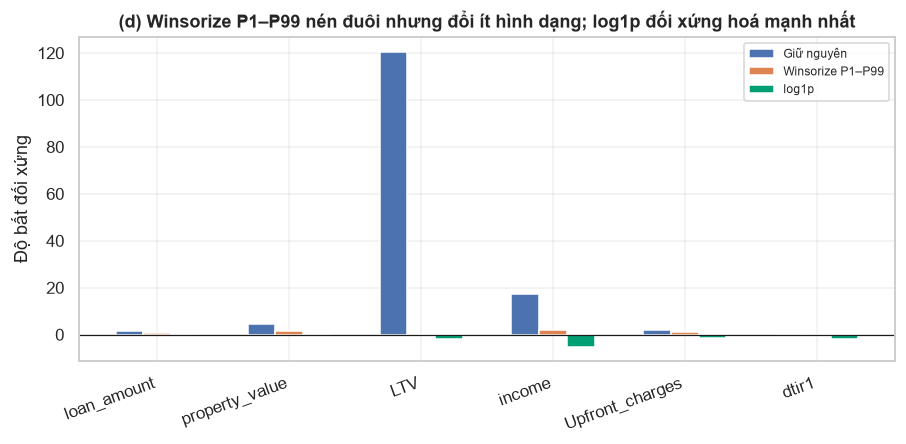

In [13]:
def winsorize(s: pd.Series, lower: float = 0.01, upper: float = 0.99) -> pd.Series:
    """Co cụm đuôi ngoài phân vị [lower, upper] về đúng bằng giá trị phân vị."""
    return s.clip(s.quantile(lower), s.quantile(upper))


W_COLS = ["loan_amount", "property_value", "LTV", "income", "Upfront_charges", "dtir1"]
eff = []
for c in W_COLS:
    s = full[c].dropna()
    w = winsorize(s)
    lg = np.log1p(s.clip(lower=0))
    n_capped = int(((s < s.quantile(.01)) | (s > s.quantile(.99))).sum())
    eff.append({
        "Trường": c,
        "Độ lệch gốc": round(float(stats.skew(s)), 2),
        "Độ lệch sau winsorize": round(float(stats.skew(w)), 3),
        "Độ lệch sau log1p": round(float(stats.skew(lg)), 3),
        "Số bị nén (2 × 1%)": n_capped,
        "Tỷ lệ bị nén (%)": round(100 * n_capped / len(s), 2),
        "Max trước": round(float(s.max()), 1),
        "Max sau winsorize": round(float(w.max()), 1),
    })
eff = pd.DataFrame(eff)
show(eff, {"Độ lệch gốc": 2, "Độ lệch sau winsorize": 3, "Độ lệch sau log1p": 3,
           "Số bị nén (2 × 1%)": 0, "Tỷ lệ bị nén (%)": 2, "Max trước": 0,
           "Max sau winsorize": 0})

# term và Credit_Score: chứng minh đây là artefact của quy tắc IQR, không winsorize
for c in ["term", "Credit_Score"]:
    s = full[c].dropna()
    q1, q3, iqr, hi, lo = iqr_bounds(s)
    print(f"{c}: Q1 = {vn(q1, 2)} | Q3 = {vn(q3, 2)} | IQR = {vn(iqr, 2)} → số điểm bị cờ = "
          f"{vn(int(((s > hi) | (s < lo)).sum()))} ({vn(100 * ((s > hi) | (s < lo)).mean(), 2)}%)"
          f" | độ bất đối xứng = {vn(stats.skew(s), 3)}")
print("→ term: IQR = 0 khiến quy tắc Tukey đánh dấu toàn bộ 26.944 kỳ hạn ngắn là ngoại lệ (đây là hiện tượng kỹ thuật do tập trung ở mốc 360 tháng, kỳ hạn thực tế 15-25 năm hoàn toàn hợp lệ); Credit_Score: phân phối đối xứng, miền [500, 900] hợp lệ. Cả hai được GIỮ NGUYÊN.")

fig, ax = plt.subplots(figsize=(8.4, 4.2))
x = np.arange(len(eff))
ax.bar(x - .21, eff["Độ lệch gốc"], .21, label="Giữ nguyên", color="#4C72B0")
ax.bar(x, eff["Độ lệch sau winsorize"], .21, label="Winsorize P1–P99", color="#DD8452")
ax.bar(x + .21, eff["Độ lệch sau log1p"], .21, label="log1p", color="#009E73")
ax.set_xticks(x, eff["Trường"], rotation=20, ha="right")
ax.axhline(0, lw=.8, color="k")
ax.set_ylabel("Độ bất đối xứng")
ax.set_title("(d) Winsorize P1–P99 nén đuôi nhưng đổi ít hình dạng; log1p đối xứng hoá mạnh nhất")
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{FIGDIR}/06_winsor_log.png"); plt.show()

### Đánh giá hiệu quả làm mịn phân phối

* **Hiệu quả của Winsorization (P1-P99):** Giới hạn phân vị tại 1% và 99% giúp đưa hệ số bất đối xứng về khoảng phù hợp: `income` giảm từ 17,31 xuống 1,81; `property_value` giảm từ 4,59 xuống 1,68; `loan_amount` giảm từ 1,67 xuống 0,75.
* **Chỉ số LTV:** Hệ số lệch của `LTV` chuyển từ 120,61 sang -0,69 khi áp trần tại 102,8%, tập trung mật độ quan sát vào vùng 60% đến 100%.
* **Tác động của biến đổi Log:** Nếu áp dụng `log1p` trước khi xử lý 1.260 giá trị 0 của trường `income`, phân phối sẽ bị lệch trái mạnh (-5,09). Do đó, `income = 0` được quy về NaN trước khi áp dụng biến đổi logarit.
* **Quy chuẩn tiền xử lý:** Winsorize cho các trường tiền tệ và tỷ lệ có đuôi nặng; áp dụng `log1p` cho 3 trường tiền tệ (`loan_amount`, `property_value`, `income`) sau khi chuyển đổi sentinel; sau đó chuẩn hóa z-score (StandardScaler) cho toàn bộ 8 trường số trong tập đặc trưng sạch.

## 2.5. So sánh thực nghiệm các phương pháp điền dữ liệu khuyết

Thực nghiệm đánh giá phương pháp điền dữ liệu được thực hiện trên các trường khuyết thiếu kỹ thuật (`income`, `Upfront_charges`, `dtir1`, `property_value`). Riêng `rate_of_interest` và `Interest_rate_spread` không tiến hành điền giá trị do tính chất trùng khớp với nhãn vỡ nợ đã được chỉ ra ở mục trước.

Quy trình thực nghiệm:
* Ẩn ngẫu nhiên 20% dữ liệu quan sát được để làm tập đánh giá.
* Ước lượng giá trị thay thế (trung bình, trung vị toàn thể, trung vị theo khu vực `Region`) trên 80% dữ liệu còn lại.
* Tính toán sai số MAE, RMSE và độ lệch hệ thống (systematic bias) trên tập 20% bị ẩn so với giá trị thực tế.

,Trường,Phương pháp,MAE,RMSE,Độ lệch so với trung vị thật
0,income,Trung vị train (80%),"3.292,91","6.390,60","0,00"
1,income,Trung bình train (80%),"3.456,32","6.261,54","1.256,37"
2,income,Trung vị theo Region (train),"3.292,20","6.388,31","4,98"
3,Upfront_charges,Trung vị train (80%),"2.406,94","3.281,22","12,44"
4,Upfront_charges,Trung bình train (80%),"2.462,77","3.228,10","635,42"
5,Upfront_charges,Trung vị theo Region (train),"2.400,74","3.275,14","17,96"
6,dtir1,Trung vị train (80%),"8,13","10,56","0,00"
7,dtir1,Trung bình train (80%),"8,19","10,49","-1,28"
8,dtir1,Trung vị theo Region (train),"8,12","10,57","0,07"
9,property_value,Trung vị train (80%),"230.768,63","379.002,59","0,00"


,Phương pháp tốt nhất (MAE),MAE tốt nhất,MAE của trung bình,Trung bình kém hơn tốt nhất (%)
Trường,,,,
Upfront_charges,Trung vị theo Region (train),"2.400,74","2.462,77","2,58"
dtir1,Trung vị theo Region (train),"8,12","8,19","0,86"
income,Trung vị theo Region (train),"3.292,20","3.456,32","4,99"
property_value,Trung vị theo Region (train),"230.537,45","239.513,01","3,89"


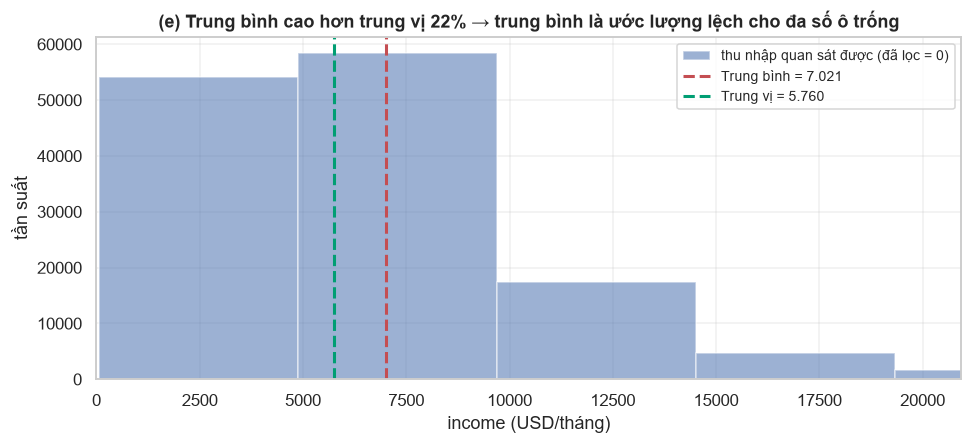

In [14]:
# Tạo bản copy riêng để chạy thực nghiệm, chuyển sentinel income = 0 về NaN
df_impute = full.copy()
df_impute["income"] = df_impute["income"].replace(0, np.nan)


def impute_experiment(col: str, groupby: pd.Series | None = None,
                      hide: float = 0.2, seed: int = RANDOM_STATE) -> pd.DataFrame:
    """Ẩn `hide` phần trăm giá trị đang quan sát, điền phần bị ẩn bằng từng
    phương pháp, trả về MAE/RMSE trên phần bị ẩn và độ lệch so với trung vị thật."""
    d = df_impute[[col]].dropna()
    rng = np.random.default_rng(seed)
    hidden = rng.random(len(d)) < hide
    train, test = d[~hidden], d[hidden]
    truth = float(d[col].median())
    variants = {"Trung vị train (80%)": float(train[col].median()),
                "Trung bình train (80%)": float(train[col].mean())}
    if groupby is not None:
        gmed = train.assign(g=groupby.loc[train.index]).groupby("g")[col].median()
        variants["Trung vị theo Region (train)"] = gmed.reindex(
            groupby.loc[test.index]).fillna(train[col].median()).to_numpy()
    rows = []
    for name, val in variants.items():
        val = np.asarray(val, dtype=float)
        err = test[col].to_numpy() - val
        rows.append({"Trường": col, "Phương pháp": name,
                     "MAE": round(float(np.abs(err).mean()), 2),
                     "RMSE": round(float(np.sqrt((err ** 2).mean())), 2),
                     "Độ lệch so với trung vị thật": round(float(np.mean(val) - truth), 2)})
    return pd.DataFrame(rows)


impe = pd.concat([impute_experiment(c, groupby=df_impute["Region"])
                  for c in ["income", "Upfront_charges", "dtir1", "property_value"]],
                 ignore_index=True)
show(impe, {"MAE": 2, "RMSE": 2, "Độ lệch so với trung vị thật": 2})

gain = impe.pivot(index="Trường", columns="Phương pháp", values="MAE")
best = gain.min(axis=1)
tab = pd.DataFrame({"Phương pháp tốt nhất (MAE)": gain.idxmin(axis=1),
                    "MAE tốt nhất": best.round(2),
                    "MAE của trung bình": gain["Trung bình train (80%)"].round(2),
                    "Trung bình kém hơn tốt nhất (%)": (100 * (gain["Trung bình train (80%)"] / best - 1)).round(2)})
show(tab, {"MAE tốt nhất": 2, "MAE của trung bình": 2, "Trung bình kém hơn tốt nhất (%)": 2})

sub = df_impute["income"].dropna()
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.hist(sub, bins=120, alpha=.55, color="#4C72B0", label="thu nhập quan sát được (đã lọc = 0)")
ax.axvline(sub.mean(), color="#C44E52", ls="--", lw=2,
           label=f"Trung bình = {vn(sub.mean())}")
ax.axvline(sub.median(), color="#009E73", ls="--", lw=2,
           label=f"Trung vị = {vn(sub.median())}")
ax.set_xlim(0, float(sub.quantile(.98)))
ax.set_xlabel("income (USD/tháng)")
ax.set_ylabel("tần suất")
ax.set_title(f"(e) Trung bình cao hơn trung vị {vn(100 * (sub.mean() / sub.median() - 1), 0)}% "
             "→ trung bình là ước lượng lệch cho đa số ô trống")
ax.legend(fontsize=9)
fig.tight_layout(); fig.savefig(f"{FIGDIR}/05_mean_median.png"); plt.show()

### Kết quả đánh giá phương pháp điền khuyết

* **Sai số MAE và RMSE:** Điền trung vị cho sai số MAE thấp hơn điền trung bình ở cả bốn trường. Khi dùng trung vị thay cho trung bình, sai số MAE giảm 4,73% ở `income`, 3,65% ở `property_value`, 2,27% ở `Upfront_charges`, và 0,73% ở `dtir1`. Phương pháp trung bình đạt RMSE thấp hơn vì về mặt toán học, giá trị trung bình là điểm tối thiểu hóa sai số bình phương trên tập dữ liệu.
* **Độ lệch vị trí:** Điền giá trị trung bình kéo ước lượng của nhóm thiếu dữ liệu lên cao hơn trung vị thực tế: `income` lệch 1.256 USD/tháng (~21,8%), `property_value` lệch 79.334 USD, và `Upfront_charges` lệch 635 USD.
* **Trung vị theo vùng:** Phân nhóm theo `Region` chỉ giảm nhẹ MAE từ 0,02% đến 0,26% tùy trường (tuyệt đối 0,01 đến 231,18 đơn vị), nhưng lại làm tăng độ lệch so với trung vị thực ở cả 3 trường tiền tệ: `income` (+4,98 USD so với 0,00 USD), `Upfront_charges` (+17,96 USD so với 12,44 USD) và `property_value` (+2.300,35 USD so với 0,00 USD).

**Phương án lựa chọn:** Điền giá trị trung vị toàn mẫu kết hợp tạo cờ báo thiếu; quy đổi `income = 0` về NaN trước khi điền; không điền giá trị cho `rate_of_interest` và `Interest_rate_spread`.

## 2.6. Hàm tiền xử lý dữ liệu tập trung

Các bước xử lý được đóng gói trong hàm `prepare()`, thực thi độc lập với nhãn `Status` để đảm bảo tính tái lập:
1. Chuyển đổi mã kỹ thuật `income = 0` về NaN.
2. Ánh xạ lại 20 trường danh mục theo từ điển nghiệp vụ (mục 1.6).
3. Chuyển đổi biến khoảng `age` thành biến số `age_mid` kèm cờ nhận diện hai đuôi tuổi.
4. Kiểm tra khả năng khôi phục `property_value` từ `LTV` theo công thức tỷ lệ `LTV = loan_amount / property_value * 100`.
5. Tạo các biến nghiệp vụ từ dữ liệu gốc trước khi điền khuyết (ví dụ: `no_upfront_fee`).
6. Winsorize P1-P99 cho các trường có đuôi phân phối dài.
7. Điền giá trị trung vị kèm cờ báo thiếu. Riêng `age_mid` điền giá trị trung vị mà không tạo cờ thiếu để tránh trùng khớp với nhãn.
8. Tính toán các tỷ lệ dẫn xuất sau tiền xử lý.
9. Tạo các biến định danh rò rỉ và xác định ngưỡng `loan_limit`.

Lưu ý: Do `LTV` và `property_value` bị khuyết đồng thời trên đúng 15.098 dòng, nhánh khôi phục giá trị qua lại không phát sinh tác dụng (`pv_recovered = 0`). Sau khi áp dụng winsorize và điền khuyết độc lập, công thức tỷ lệ toán học giữa hai trường này không còn được bảo toàn nguyên vẹn, do đó hai biến được sử dụng như hai đặc trưng độc lập trong mô hình.

In [15]:
RENAME = {c: {k: v[0] for k, v in m.items()} for c, m in CODEBOOK.items()}
AGE_MID = {"<25": 20, "25-34": 29.5, "35-44": 39.5, "45-54": 49.5,
           "55-64": 59.5, "65-74": 69.5, ">74": 79}
CONFORMING_CAP = 500_000          # ngưỡng "hạn mức chuẩn" quy ước (dữ liệu bucket 500 USD)

WINSOR_COLS = ["loan_amount", "property_value", "LTV", "income", "Upfront_charges", "dtir1"]
MEDIAN_IMPUTE = ["income", "Upfront_charges", "dtir1", "property_value", "LTV", "term"]
DROP_COLS = ["year", "ID", "Interest_rate_spread", "age", "total_units",
             "Security_Type", "construction_type", "Secured_by",
             "open_credit", "co-applicant_credit_type_raw", "leak_flag"]


def prepare(df: pd.DataFrame) -> pd.DataFrame:
    """Làm sạch + kỹ thuật đặc trưng MỘT CHIỀU (không đọc nhãn Status)."""
    out = df.copy()

    # (1) Sentinel kỹ thuật → NaN (income = 0 không phải thu nhập thật)
    out["income"] = out["income"].replace(0, np.nan)

    # (2) Tái mã hoá 20 trường phân loại theo CODEBOOK (mục 1.6); age xử lý ở bước (3)
    for c, mp in RENAME.items():
        if c in out.columns:
            out[c] = out[c].map(mp).fillna(out[c])

    # (3) age là khoảng → midpoint số + cờ hai đuôi
    out["age_mid"] = out["age"].map(AGE_MID).astype(float)
    out["age_lt25"] = out["age"].eq("<25").astype(int)
    out["age_gt74"] = out["age"].eq(">74").astype(int)

    # (4) Phục hồi bằng đồng nhất thức LTV = loan_amount / property_value × 100
    no_pv = out["property_value"].isna() & out["LTV"].notna() & (out["LTV"] > 0)
    out.loc[no_pv, "property_value"] = (out.loc[no_pv, "loan_amount"]
                                        / (out.loc[no_pv, "LTV"] / 100))
    no_ltv = out["LTV"].isna() & out["property_value"].notna() & (out["property_value"] > 0)
    out.loc[no_ltv, "LTV"] = (out.loc[no_ltv, "loan_amount"]
                              / out.loc[no_ltv, "property_value"] * 100)
    out["pv_recovered"] = no_pv.astype(int)      # ghi nhận phục hồi (không phải điền đoán)

    # (5) Đặc trưng nghiệp vụ sinh từ trường gốc phục vụ kiểm toán (không nạp X_clean để giữ mô hình tinh gọn)
    out["no_upfront_fee"] = out["Upfront_charges"].eq(0).astype(int)
    out["multi_unit"] = out["total_units"].astype(str).str.extract(r"(\d)").astype(float)
    out["is_investment_property"] = out["occupancy_type"].str.startswith("Đầu tư").astype(int)
    out["neg_amm"] = out["Neg_ammortization"].eq("Trả dần âm").astype(int)
    out["int_only"] = out["interest_only"].eq("Chỉ trả lãi").astype(int)
    out["lump_sum"] = out["lump_sum_payment"].eq("Trả một lần cuối kỳ").astype(int)
    out["pre_approved"] = out["approv_in_adv"].eq("Được phê duyệt trước").astype(int)

    # (6) Winsorize P1–P99 cho nhóm đuôi nặng (không đụng term / Credit_Score)
    for c in WINSOR_COLS:
        out[c] = winsorize(out[c])

    # (7) Điền trung vị toàn mẫu + cờ thiếu (chiến lược chốt ở mục 2.5)
    for c in MEDIAN_IMPUTE:
        if c == "term":
            out[c] = out[c].fillna(out[c].median())          # 0,03% → không cần cờ
        elif c == "LTV":
            out["ltv_missing"] = out["LTV"].isna().astype(int)
            out["LTV"] = out["LTV"].fillna(out["LTV"].median())
        else:
            out[f"{c}_missing"] = out[c].isna().astype(int)
            out[c] = out[c].fillna(out[c].median())

    # (7b) age_mid còn 200 ô trống (đúng nhóm rò rỉ L5): điền trung vị để không
    #      làm hỏng bước chuẩn hoá z-score, và CỐ Ý KHÔNG sinh cờ thiếu cho tuổi,
    #      vì cờ này trùng khít với nhãn (đầy đủ dữ liệu đối với mô hình sạch rồi).
    out["age_mid"] = out["age_mid"].fillna(out["age_mid"].median())

    # (8) Tỷ lệ dẫn xuất trên thang đã xử lý
    out["monthly_payment_proxy"] = out["loan_amount"] / out["term"].clip(lower=1)
    out["payment_to_income"] = out["monthly_payment_proxy"] / out["income"].clip(lower=1)
    out["loan_over_conforming"] = (out["loan_amount"] > CONFORMING_CAP).astype(int)
    out["ltv_above_100"] = (out["LTV"] > 100).astype(int)
    out["loan_limit_suy"] = np.where(out["loan_over_conforming"] == 1,
                                     "Non-conforming - vượt hạn chuẩn",
                                     "Conforming - hạn mức chuẩn")

    # (9) Cờ rò rỉ: CHỈ để định lượng (tập nhiễm rò rỉ), không bao giờ vào tập sạch
    out["roi_missing"] = out["rate_of_interest"].isna().astype(int)
    out["spread_missing"] = out["Interest_rate_spread"].isna().astype(int)

    return out.drop(columns=[c for c in DROP_COLS if c in out.columns])


mfc = prepare(full)
print(f"Khung mô hình: {vn(len(mfc))} dòng × {mfc.shape[1]} cột | "
      f"tỷ lệ vỡ nợ {vn(100 * mfc[TARGET].mean(), 2)}%")
still_na = {k: int(v) for k, v in mfc.isna().sum().items() if v > 0}
print("Cột còn NaN sau prepare() (rate_of_interest giữ nguyên; phân loại điền trong pipeline):",
      {k: vn(v) for k, v in still_na.items()})
# Kiểm chứng đồng nhất thức LTV sau làm sạch (winsorize + điền độc lập)
_obs = raw["property_value"].notna() & raw["LTV"].notna()
_ltv_dev = mfc["LTV"] - mfc["loan_amount"] / mfc["property_value"] * 100
_obs_dev_gt1 = (_ltv_dev[_obs].abs() > 1)
print(f"  Tỷ lệ vỡ nợ nhóm lệch LTV >1 pp: {vn(100 * raw.loc[_obs & _obs_dev_gt1, TARGET].mean(), 2)}% (nền {vn(100 * raw[TARGET].mean(), 2)}%); sai lệch tập trung ở nhóm rủi ro cao do LTV bị trần P99 = 102,76%.")
print(f"Đồng nhất thức LTV sau làm sạch: dòng quan sát lệch >1 điểm %: "
      f"{vn((_ltv_dev[_obs].abs() > 1).sum())} ({vn(100 * (_ltv_dev[_obs].abs() > 1).mean(), 2)}%), "
      f"max {vn(_ltv_dev.abs().max(), 2)} | dòng điền lệch: "
      f"{vn(100 * (_ltv_dev[~_obs].abs() > 1).mean(), 1)}% | pv_recovered = {vn(int(mfc['pv_recovered'].sum()))}")
show(mfc.head(3).T)

Khung mô hình: 148.670 dòng × 48 cột | tỷ lệ vỡ nợ 24,64%
Cột còn NaN sau prepare() (rate_of_interest giữ nguyên; phân loại điền trong pipeline): {'loan_limit': '3.344', 'approv_in_adv': '908', 'loan_purpose': '134', 'rate_of_interest': '36.439', 'Neg_ammortization': '121', 'submission_of_application': '200'}
  Tỷ lệ vỡ nợ nhóm lệch LTV >1 pp: 39,45% (nền 24,64%); sai lệch tập trung ở nhóm rủi ro cao do LTV bị trần P99 = 102,76%.
Đồng nhất thức LTV sau làm sạch: dòng quan sát lệch >1 điểm %: 5.059 (3,79%), max 609,17 | dòng điền lệch: 98,1% | pv_recovered = 0


,0,1,2
loan_limit,Conforming - hạn mức chuẩn,Conforming - hạn mức chuẩn,Conforming - hạn mức chuẩn
Gender,Không công khai giới tính,Nam,Nam
approv_in_adv,Không phê duyệt trước,Không phê duyệt trước,Được phê duyệt trước
loan_type,Loại 1,Loại 2,Loại 1
loan_purpose,Mục đích 1,Mục đích 1,Mục đích 1
Credit_Worthiness,Hạng tín dụng L1,Hạng tín dụng L1,Hạng tín dụng L1
business_or_commercial,Mục đích cá nhân,Mục đích kinh doanh/thương mại,Mục đích cá nhân
loan_amount,116.500,206.500,406.500
rate_of_interest,,,"4,56"
Upfront_charges,"2.596,45","2.596,45",595


## 2.7. Thiết lập không gian đặc trưng và hành lang so sánh

Dữ liệu được tổ chức thành hai cấu trúc phục vụ cho các mục tiêu phân tích khác nhau:

* `X_clean` (Tập đặc trưng sạch): Gồm các trường thông tin cốt lõi quan sát được tại thời điểm thẩm định trước khi giải ngân: 8 thuộc tính định lượng (`loan_amount`, `property_value`, `LTV`, `income`, `dtir1`, `Credit_Score`, `term`, `age_mid`) và 13 biến danh mục đã chuẩn hóa. Các biến phái sinh (như tỷ lệ trả góp, cờ phân loại hạn mức) chỉ tạo trên `mfc` trong bước khám phá dữ liệu, không đưa vào `X_clean` để giữ mô hình tinh gọn và tránh cộng tuyến với các trường gốc. Loại bỏ `rate_of_interest`, `Interest_rate_spread`, các cờ báo thiếu và toàn bộ cột `credit_type` (do 99,99% bản ghi EQUI là vỡ nợ, kéo theo cột này mang tín hiệu phân tách giả). Riêng `submission_of_application` được điền bằng giá trị xuất hiện nhiều nhất (mode) ước lượng trên tập huấn luyện để tránh việc mã hóa one-hot tạo ra nhóm trùng khớp với nhãn.
* `arena` (Hành lang so sánh): Tập con các hồ sơ có đầy đủ cả bốn trường thông tin định giá (`property_value`, `LTV`, `dtir1`, `income`) sau khi phục hồi bằng đồng nhất thức, tạo cơ sở so sánh giữa các nhóm hồ sơ có cùng mức độ đầy đủ thông tin.

Quy trình phân chia dữ liệu áp dụng phân tầng (`stratify`) theo nhãn `Status` để bảo toàn tỷ lệ vỡ nợ 24,64% trên cả tập train và test. Các bước biến đổi `StandardScaler` và `OneHotEncoder` chỉ fit trên tập huấn luyện.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ---- (i) Danh sách đặc trưng ----
NUM_CLEAN = ["loan_amount", "property_value", "LTV", "income", "dtir1",
             "Credit_Score", "term", "age_mid"]
CAT_CLEAN = ["Gender", "Region", "loan_limit", "loan_type", "occupancy_type",
             "business_or_commercial", "Credit_Worthiness", "loan_purpose",
             "Neg_ammortization", "interest_only", "lump_sum_payment",
             "co-applicant_credit_type", "submission_of_application"]
LOG_FEATS = ["loan_amount", "property_value", "income"]
# 5 cờ đại diện cho 4 tín hiệu khác nhau (property_value_missing và ltv_missing trùng khít 15.098 dòng sau phục hồi đồng nhất thức)
MISS_FLAGS = ["roi_missing", "property_value_missing", "Upfront_charges_missing",
              "dtir1_missing", "ltv_missing"]

y = mfc[TARGET].astype(int)

# ---- (ii) Hành lang so sánh: giữ dòng có ĐỦ BỐN trường định giá quan sát được ----
arena_mask = (mfc["property_value_missing"].eq(0) & mfc["ltv_missing"].eq(0)
              & mfc["dtir1_missing"].eq(0) & mfc["income_missing"].eq(0))
arena = mfc[arena_mask].copy()
print(f"Hành lang so sánh: {vn(len(arena))} dòng ({vn(100 * len(arena) / len(mfc), 2)}% mẫu), "
      f"tỷ lệ vỡ nợ {vn(100 * arena[TARGET].mean(), 2)}% (toàn mẫu {vn(100 * y.mean(), 2)}%).")
print("  → mặc định nghĩa của hành lang: loại bỏ hồ sơ thiếu định giá, nên tự nó "
      "đã làm giàu nhóm trả nợ đúng hạn; đây là lý do chỉ số ở đây không thể so "
      "trực tiếp với chỉ toàn mẫu.")

# ---- (iii) Ma trận đặc trưng ----
def log1p_money(X: pd.DataFrame) -> pd.DataFrame:
    """Chỉ nhóm tiền tệ qua log1p; tỷ lệ/điểm giữ thang nguyên (mục 2.4)."""
    for c in LOG_FEATS:
        if c in X.columns:
            X[c] = np.log1p(X[c].clip(lower=0))
    return X

X_clean = log1p_money(mfc[NUM_CLEAN + CAT_CLEAN].copy())

Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(
    X_clean, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

print(f"X_clean: {X_clean.shape[1]} cột (train {vn(len(Xc_tr))} / test {vn(len(Xc_te))})")
print(f"Tỷ lệ vỡ nợ: train {vn(100 * yc_tr.mean(), 2)}% / test {vn(100 * yc_te.mean(), 2)}%"
      f" | toàn mẫu {vn(100 * y.mean(), 2)}% → stratify giữ nguyên tỷ lệ")

# ---- (iv) Bộ tiền xử lý: chỉ fit trên TRAIN ----
#   số: StandardScaler (không còn NaN sau mục 2.6);
#   phân loại: điền nhãn "(không rõ)" cho loan_limit (3.344), approv_in_adv (908),
#   loan_purpose (134), Neg_ammortization (121); riêng submission_of_application
#   (200 dòng, toàn bộ là vỡ nợ) điền mode để không tạo mức trùng khớp nhãn.
def make_pre(num: list[str], cat: list[str]) -> ColumnTransformer:
    from sklearn.pipeline import Pipeline
    from sklearn.impute import SimpleImputer

    # submission_of_application: 200 dòng trống đều là vỡ nợ (nhóm B, mục 2.1).
    # Điền hằng "(không rõ)" sẽ tạo một mức trùng khít nhãn → riêng cột này
    # điền mode (fit trên train) và không sinh mức "(không rõ)".
    cat_mode = [c for c in cat if c == "submission_of_application"]
    cat_const = [c for c in cat if c not in cat_mode]
    return ColumnTransformer(transformers=[
        ("num", StandardScaler(), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant",
                                                 fill_value="(không rõ)")),
                          ("oh", OneHotEncoder(drop="first", handle_unknown="ignore"))]),
         cat_const),
        ("cat_mode", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                               ("oh", OneHotEncoder(drop="first", handle_unknown="ignore"))]),
         cat_mode),
    ])

pre_clean = make_pre(NUM_CLEAN, CAT_CLEAN)

# ---- (v) Đối chiếu loan_limit gốc với ngưỡng conforming quy ước ----
ct = pd.crosstab(mfc["loan_limit"], mfc["loan_limit_suy"])
show(ct, {c: 0 for c in ct.columns})
agree = float(np.trace(ct.values) / ct.values.sum())
print(f"Tỷ lệ thống nhất giữa nhãn gốc và cách suy theo ngưỡng 500.000 USD: {vn(100 * agree, 2)}%")

Hành lang so sánh: 124.089 dòng (83,47% mẫu), tỷ lệ vỡ nợ 16,10% (toàn mẫu 24,64%).
  → mặc định nghĩa của hành lang: loại bỏ hồ sơ thiếu định giá, nên tự nó đã làm giàu nhóm trả nợ đúng hạn; đây là lý do chỉ số ở đây không thể so trực tiếp với chỉ toàn mẫu.


X_clean: 21 cột (train 111.502 / test 37.168)
Tỷ lệ vỡ nợ: train 24,64% / test 24,64% | toàn mẫu 24,64% → stratify giữ nguyên tỷ lệ


loan_limit_suy,Conforming - hạn mức chuẩn,Non-conforming - vượt hạn chuẩn
loan_limit,,
Conforming - hạn mức chuẩn,117.591,17.757
Non-conforming - vượt hạn chuẩn,5.180,4.798


Tỷ lệ thống nhất giữa nhãn gốc và cách suy theo ngưỡng 500.000 USD: 84,22%


### Kiểm tra phân phối tập huấn luyện và kiểm tra

Đối chiếu giá trị trung bình và phân phối của các đặc trưng số giữa tập train và test nhằm xác nhận tính đồng nhất sau khi phân chia dữ liệu. Danh sách thuộc tính của `X_clean` được hiển thị để xác nhận không chứa các trường lãi suất hoặc cờ khuyết thiếu.

In [17]:
# (i) Trùng lặp train/test: so sánh trung bình của đặc trưng số sạch
cmp = pd.DataFrame({
    "Trung bình train": Xc_tr[NUM_CLEAN].mean().round(3),
    "Trung bình test": Xc_te[NUM_CLEAN].mean().round(3),
    "Độ lệch chuẩn train": Xc_tr[NUM_CLEAN].std().round(3),
})
cmp["Chênh lệch tương đối (%)"] = (100 * (cmp["Trung bình test"] / cmp["Trung bình train"] - 1)
                                 .abs()).round(3)
show(cmp.sort_values("Chênh lệch tương đối (%)", ascending=False),
         {"Trung bình train": 3, "Trung bình test": 3,
          "Độ lệch chuẩn train": 3, "Chênh lệch tương đối (%)": 3})
print(f"Trung bình chênh lệch tương đối train/test: "
      f"{vn(cmp['Chênh lệch tương đối (%)'].mean(), 3)}% → phép chia nhất quán; lưu ý: "
      f"trung vị/phân vị được ước lượng trên toàn mẫu trước khi chia (xem mục 4.5).")

# (ii) Danh sách đặc trưng sạch mà mô hình được phép nhìn
feature_doc = pd.DataFrame({
    "Đặc trưng": list(NUM_CLEAN) + list(CAT_CLEAN),
    "Nhóm": (["tiền tệ (log1p + z-score)" if c in LOG_FEATS else "số (z-score)" for c in NUM_CLEAN]
             + ["phân loại (one-hot)" for _ in CAT_CLEAN]),
    "Số giá trị": [int(X_clean[c].nunique()) for c in NUM_CLEAN + CAT_CLEAN],
})
show(feature_doc, {"Số giá trị": 0})
print("Ghi chú: Cột 'Số giá trị' của biến số tính trên X_clean sau winsorize P1-P99 (ví dụ loan_amount còn 80 mức phân biệt so với 211 mức ở dữ liệu thô do nén 2 đầu đuôi).")

# (iii) Xác nhận tập SẠCH không chứa bất kỳ trường thiếu/rò rỉ nào
leak_substr = ("missing", "roi", "spread", "rate_of_interest")
in_clean = [c for c in X_clean.columns if any(w in c.lower() for w in leak_substr) or c == "credit_type"]
print("Trường rò rỉ theo tên cột trong X_clean:", in_clean if in_clean else "(không có — đạt yêu cầu)")

,Trung bình train,Trung bình test,Độ lệch chuẩn train,Chênh lệch tương đối (%)
loan_amount,"12,554","12,565","0,564","0,088"
dtir1,"37,943","37,971","9,603","0,074"
property_value,"12,926","12,935","0,572","0,070"
age_mid,"50,848","50,876","14,110","0,055"
term,"335,173","335,055","58,328","0,035"
income,"8,648","8,651","0,588","0,035"
Credit_Score,"699,767","699,856","115,862","0,013"
LTV,"72,768","72,771","17,635","0,004"


Trung bình chênh lệch tương đối train/test: 0,047% → phép chia nhất quán; lưu ý: trung vị/phân vị được ước lượng trên toàn mẫu trước khi chia (xem mục 4.5).


,Đặc trưng,Nhóm,Số giá trị
0,loan_amount,tiền tệ (log1p + z-score),80
1,property_value,tiền tệ (log1p + z-score),173
2,LTV,số (z-score),7.303
3,income,tiền tệ (log1p + z-score),427
4,dtir1,số (z-score),53
5,Credit_Score,số (z-score),401
6,term,số (z-score),26
7,age_mid,số (z-score),7
8,Gender,phân loại (one-hot),4
9,Region,phân loại (one-hot),4


Ghi chú: Cột 'Số giá trị' của biến số tính trên X_clean sau winsorize P1-P99 (ví dụ loan_amount còn 80 mức phân biệt so với 211 mức ở dữ liệu thô do nén 2 đầu đuôi).
Trường rò rỉ theo tên cột trong X_clean: (không có — đạt yêu cầu)


# Phần 3. Kiểm định giả thuyết và phân tích tương quan

Phần này kiểm định sáu giả thuyết nghiệp vụ về rủi ro tín dụng trên khung phân tích đầy đủ (`mfc`) và hành lang so sánh (`arena`):
* H1: Điểm tín dụng tỷ lệ nghịch với xác suất vỡ nợ.
* H2: Lãi suất phản ánh mức độ rủi ro của khoản vay (định giá theo rủi ro).
* H3: Đòn bẩy tài chính (LTV) tỷ lệ thuận với khả năng vỡ nợ.
* H4: Tỷ lệ nợ trên thu nhập (DTI) có quan hệ đơn điệu với rủi ro vỡ nợ.
* H5: Mức thu nhập tỷ lệ nghịch với rủi ro vỡ nợ.
* H6: Cấu trúc sản phẩm vay (phương thức trả gốc, khấu hao âm, người đồng nộp đơn) liên kết với rủi ro vỡ nợ.

## 3.1. Phương pháp và công cụ thống kê

Đo lường mức độ liên kết giữa các biến phân loại và nhãn mục tiêu bằng hệ số Cramér's V bên cạnh giá trị p-value từ kiểm định Chi-square. Với cỡ mẫu lớn (148.670 dòng), p-value dễ dàng đạt mức ý nghĩa thống kê ($p < 0,05$), do đó hệ số Cramér's V cung cấp thông tin về độ lớn thực tế của mối liên kết:
* $V < 0,10$: Mối liên kết yếu.
* $0,10 \le V \le 0,30$: Mức độ liên kết trung bình.
* $V > 0,30$: Mối liên kết chặt chẽ.

In [18]:
def cramers_v(x, y) -> tuple:
    """Cường độ liên kết danh định - nhãn: trả về Cramér's V, chi2, p."""
    ct = pd.crosstab(x, y)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    n, r, k = ct.values.sum(), *ct.shape
    v = np.sqrt(chi2 / (n * (min(r, k) - 1)))
    return v, chi2, p


def band_rate(frame: pd.DataFrame, col: str, bins, labels=None) -> pd.DataFrame:
    """Tỷ lệ vỡ nợ từng dải của biến liên tục (không đọc nhãn ở khâu phân dải)."""
    tmp = frame.assign(_b=pd.cut(frame[col], bins=bins, labels=labels, include_lowest=True))
    g = tmp.groupby("_b", observed=True)[TARGET].agg(
        **{"Số dòng": "size", "Tỷ lệ vỡ nợ (%)": "mean"})
    g["Tỷ lệ vỡ nợ (%)"] = (100 * g["Tỷ lệ vỡ nợ (%)"]).round(2)
    return g


def cat_signal(col: str, frame: pd.DataFrame = None):
    """Bang ti le default theo nhom + cuong do lien ket (V, chi2, p)."""
    f = mfc if frame is None else frame
    g = (f.groupby(col, observed=True)[TARGET]
           .agg(**{"Số dòng": "size", "Tỷ lệ vỡ nợ (%)": "mean"})
           .sort_values("Tỷ lệ vỡ nợ (%)", ascending=False))
    g["Tỷ lệ vỡ nợ (%)"] = (100 * g["Tỷ lệ vỡ nợ (%)"]).round(2)
    v, chi2, p = cramers_v(f[col], f[TARGET])
    return g, chi2, p, v


print(f"Toàn mẫu: {vn(len(mfc))} dòng, tỷ lệ vỡ nợ {vn(100 * mfc[TARGET].mean(), 2)}%  "
      f"| Hành lang arena: {vn(len(arena))} dòng, tỷ lệ vỡ nợ {vn(100 * arena[TARGET].mean(), 2)}%")

Toàn mẫu: 148.670 dòng, tỷ lệ vỡ nợ 24,64%  | Hành lang arena: 124.089 dòng, tỷ lệ vỡ nợ 16,10%


## 3.2. Kiểm định H1: Năng lực dự báo của Điểm tín dụng

Phương pháp: Phân chia `Credit_Score` thành bốn nhóm chuẩn bán lẻ (< 620, 620-680, 680-740, > 740), đo lường tỷ lệ vỡ nợ theo từng nhóm, tính hệ số Cramér's V và ROC-AUC đơn biến của điểm tín dụng.

,Số dòng,Tỷ lệ vỡ nợ (%)
_b,,
< 620,45.103,"24,66"
620-680,22.250,"24,38"
680-740,22.085,"24,13"
> 740,59.232,"24,93"


H1: Cramér's V = 0,0066 | χ² = 6,5 (p = 0,090) | AUC(Credit_Score đơn biến) = 0,5027
    Độ lệch chuẩn Credit_Score = 115,9 | phương sai = 13.427,2 | trung vị = 699


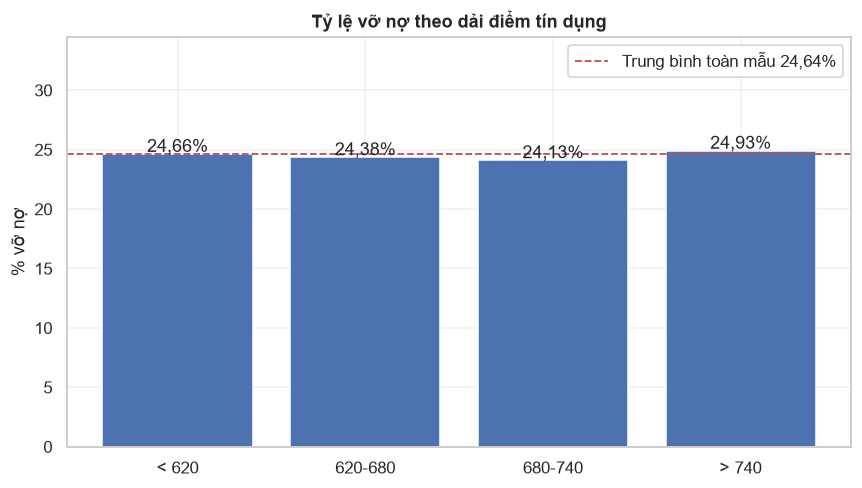

In [19]:
CS_BINS, CS_LAB = [0, 620, 680, 740, 9999], ["< 620", "620-680", "680-740", "> 740"]
h1 = band_rate(mfc, "Credit_Score", CS_BINS, CS_LAB)
show(h1, {"Số dòng": 0, "Tỷ lệ vỡ nợ (%)": 2})

cs_bin = pd.cut(mfc["Credit_Score"], CS_BINS, labels=CS_LAB, include_lowest=True)
v1, chi2_1, p1 = cramers_v(cs_bin, mfc[TARGET])
auc1 = roc_auc_score(mfc[TARGET], mfc["Credit_Score"])
print(f"H1: Cramér's V = {vn(v1, 4)} | χ² = {vn(chi2_1, 1)} (p = {vn(p1, 3)}) | "
      f"AUC(Credit_Score đơn biến) = {vn(auc1, 4)}")
print(f"    Độ lệch chuẩn Credit_Score = {vn(mfc['Credit_Score'].std(), 1)} | "
      f"phương sai = {vn(mfc['Credit_Score'].var(), 1)} | trung vị = {vn(mfc['Credit_Score'].median(), 0)}")

fig, ax = plt.subplots(figsize=(8, 4.6))
base = 100 * mfc[TARGET].mean()
bars = ax.bar(h1.index.astype(str), h1["Tỷ lệ vỡ nợ (%)"], color="#4C72B0")
ax.axhline(base, color="#C44E52", ls="--", lw=1.2, label=f"Trung bình toàn mẫu {vn(base, 2)}%")
for b, val in zip(bars, h1["Tỷ lệ vỡ nợ (%)"]):
    ax.text(b.get_x() + b.get_width() / 2, val + 0.15, f"{vn(val, 2)}%", ha="center")
ax.set_ylim(0, base * 1.4); ax.set_ylabel("% vỡ nợ")
ax.set_title("Tỷ lệ vỡ nợ theo dải điểm tín dụng")
ax.legend(framealpha=.9); fig.tight_layout()
fig.savefig(f"{FIGDIR}/10_h1_credit_score.png"); plt.show()

### Kết quả phân tích H1: Điểm tín dụng và tỷ lệ vỡ nợ

Tỷ lệ vỡ nợ phân bổ qua bốn phân khúc điểm tín dụng lần lượt là 24,66%, 24,38%, 24,13% và 24,93% (mức chênh lệch tối đa chỉ 0,8%). Hệ số Cramér's V đạt 0,0066 ($\chi^2 = 6,5; p = 0,090$) và ROC-AUC đơn biến bằng 0,5027, tương đương với mức phân loại ngẫu nhiên.

Mặc dù `Credit_Score` có độ biến thiên cao (độ lệch chuẩn 115,9, trung vị 699), phân phối này không mang thông tin phân tách giữa hai lớp nhãn. Biến này không có vai trò dự báo trong mô hình chấm điểm trên tập dữ liệu này.

## 3.3. Kiểm định H2: Cơ chế định giá lãi suất theo rủi ro

Phương pháp: Đánh giá mối tương quan Spearman giữa lãi suất (`rate_of_interest`) và tỷ lệ đòn bẩy (`LTV`) trên tập hợp các hồ sơ có ghi nhận lãi suất (112.231 dòng). Với 200 ca vỡ nợ có thông tin lãi suất, sử dụng kiểm định Welch t-test để so sánh mức lãi suất bình quân với nhóm trả nợ đúng hạn.

H2: Spearman(lãi suất, LTV) = 0,0298 (p = 0,0000) | n = 112.231


,Số dòng,Lãi suất trung bình,Trung vị,Độ lệch chuẩn
LTV,,,,
<=60,28.040,"3,9877","3,9900","0,5896"
60-80,43.489,"4,0961","3,9900","0,5555"
80-100,40.074,"4,0342","3,9900","0,5421"
100-120,628,"3,8339","3,7500","0,5511"


,Số hồ sơ,Trung bình,Trung vị
Trả nợ đúng hạn,112.031,"4,0449","3,9900"
Vỡ nợ,200,"4,3505","4,3125"


Welch t-test (lãi suất nhóm vỡ nợ so với nhóm lành): t = 8,71 | p = 0,0000


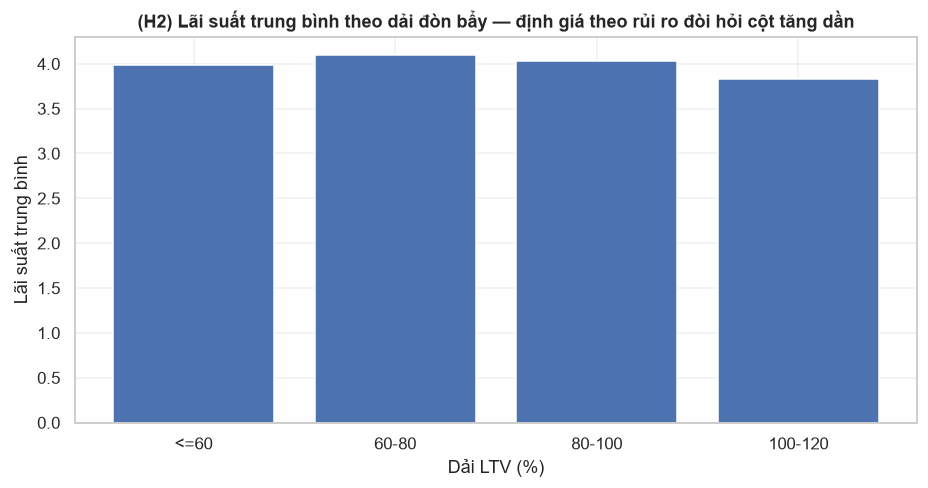

In [20]:
# H2 — Định giá lãi suất theo rủi ro: lãi suất có tăng theo LTV không?
# Phạm vi: chỉ dòng QUAN SÁT ĐƯỢC lãi suất (dòng thiếu lãi suất = cụm rò rỉ mục 1.8,
# đưa vào sẽ biến phép thử "định giá" thành phép thử "nhãn").
h2sub = mfc[mfc["rate_of_interest"].notna() & mfc["LTV"].notna()]
r_h2, p_h2 = stats.spearmanr(h2sub["rate_of_interest"], h2sub["LTV"])
print(f"H2: Spearman(lãi suất, LTV) = {vn(r_h2, 4)} (p = {vn(p_h2, 4)}) | n = {vn(len(h2sub))}")

# Gradient lãi suất theo dải LTV — nếu định giá theo rủi ro thì phải tăng đơn điệu
LTV_EDGES = [0, 60, 80, 100, 120, 9999]
LTV_LAB_H2 = ["<=60", "60-80", "80-100", "100-120", ">120"]
roi_band = pd.cut(h2sub["LTV"], LTV_EDGES, labels=LTV_LAB_H2)
grad = (h2sub.groupby(roi_band, observed=True)["rate_of_interest"]
        .agg(so_dong="count", roi_trungbinh="mean", roi_trungvi="median", roi_std="std")
        .round(4)
        .rename(columns={"so_dong": "Số dòng", "roi_trungbinh": "Lãi suất trung bình",
                          "roi_trungvi": "Trung vị", "roi_std": "Độ lệch chuẩn"}))
show(grad, {"Số dòng": 0, "Lãi suất trung bình": 4, "Trung vị": 4, "Độ lệch chuẩn": 4})

# 200 ca vỡ nợ "thoát" (có lãi suất) so với hồ sơ lành: lãi suất có khác biệt?
by_lbl = (h2sub.groupby(TARGET)["rate_of_interest"].agg(["count", "mean", "median"]).round(4)
          .rename(columns={"count": "Số hồ sơ", "mean": "Trung bình", "median": "Trung vị"}))
by_lbl.index = ["Trả nợ đúng hạn", "Vỡ nợ"]
show(by_lbl, {"Số hồ sơ": 0, "Trung bình": 4, "Trung vị": 4})
t_h2, p_ttest = stats.ttest_ind(h2sub.loc[h2sub[TARGET] == 1, "rate_of_interest"],
                                h2sub.loc[h2sub[TARGET] == 0, "rate_of_interest"],
                                equal_var=False)
print(f"Welch t-test (lãi suất nhóm vỡ nợ so với nhóm lành): t = {vn(t_h2, 2)} | p = {vn(p_ttest, 4)}")

fig, ax = plt.subplots(figsize=(8.6, 4.6))
ax.bar(grad.index.astype(str), grad["Lãi suất trung bình"], color="#4C72B0")
ax.set_ylabel("Lãi suất trung bình")
ax.set_xlabel("Dải LTV (%)")
ax.set_title("(H2) Lãi suất trung bình theo dải đòn bẩy — định giá theo rủi ro đòi hỏi cột tăng dần")
fig.tight_layout(); fig.savefig(f"{FIGDIR}/10b_h2_pricing.png"); plt.show()

### Kết quả phân tích H2: Lãi suất và đòn bẩy tài chính

* **Tương quan giữa lãi suất và LTV:** Hệ số tương quan Spearman giữa lãi suất và LTV đạt +0,0298 trên mẫu 112.231 dòng có lãi suất. Mặc dù $p < 0,001$ do cỡ mẫu lớn, độ lớn hiệu ứng thực tế gần như bằng 0. Lãi suất trung bình theo các khoảng LTV không tăng đơn điệu (lần lượt là 3,99%, 4,10%, 4,03% và 3,83%).
* **Nhóm 200 ca vỡ nợ có lãi suất:** Mức lãi suất trung bình của nhóm này là 4,35%, cao hơn mức 4,04% của nhóm hồ sơ trả nợ đúng hạn (kiểm định Welch t = 8,71). Tuy nhiên, nhóm này chỉ chiếm 0,55% tổng số ca vỡ nợ và mức chênh lệch khoảng 0,3% chưa tương xứng với phần bù rủi ro thông thường.

## 3.4. Kiểm định H3-H5: Các yếu tố rủi ro định lượng (LTV, DTI, Thu nhập)

Khảo sát hình dạng phân bố tỷ lệ vỡ nợ theo từng khoảng giá trị trên hành lang `arena` nhằm tránh nhiễu từ các giá trị điền khuyết:
* H3: Đòn bẩy tài chính (`LTV`).
* H4: Tỷ lệ nợ trên thu nhập (`dtir1`).
* H5: Mức thu nhập (`income`).

Các kiểm định phi tham số gồm: Kruskal-Wallis cho biến độ tuổi, Mann-Whitney U và kiểm định phương sai Levene cho tỷ lệ LTV giữa hai nhóm nhãn.

_b
(0; 60]       13,71
(60; 80]      12,82
(80; 100]     19,82
(100; 120]    66,91
Name: Tỷ lệ vỡ nợ (%), dtype: str

_b
(0; 20]     20,98
(20; 30]    12,07
(30; 40]    12,21
(40; 50]    15,54
(50; 60]    42,73
Name: Tỷ lệ vỡ nợ (%), dtype: str

_b
<=3k      27,70
3-4.5k    18,53
4.5-6k    14,88
6-8k      12,60
8-12k     11,09
>12k      12,10
Name: Tỷ lệ vỡ nợ (%), dtype: str

_b
<=100k      27,65
100-150k    20,01
150-200k    18,71
200-300k    16,01
300-500k    13,29
500-700k    11,84
>700k       24,17
Name: Tỷ lệ vỡ nợ (%), dtype: str

_b
<=180         23,84
(180; 240]    20,93
(240; 330]    39,51
330-360       24,19
Name: Tỷ lệ vỡ nợ (%), dtype: str

_b
<25      28,95
25-34    22,19
35-44    22,27
45-54    24,48
55-64    25,89
65-74    26,86
>74      30,01
Name: Tỷ lệ vỡ nợ (%), dtype: str

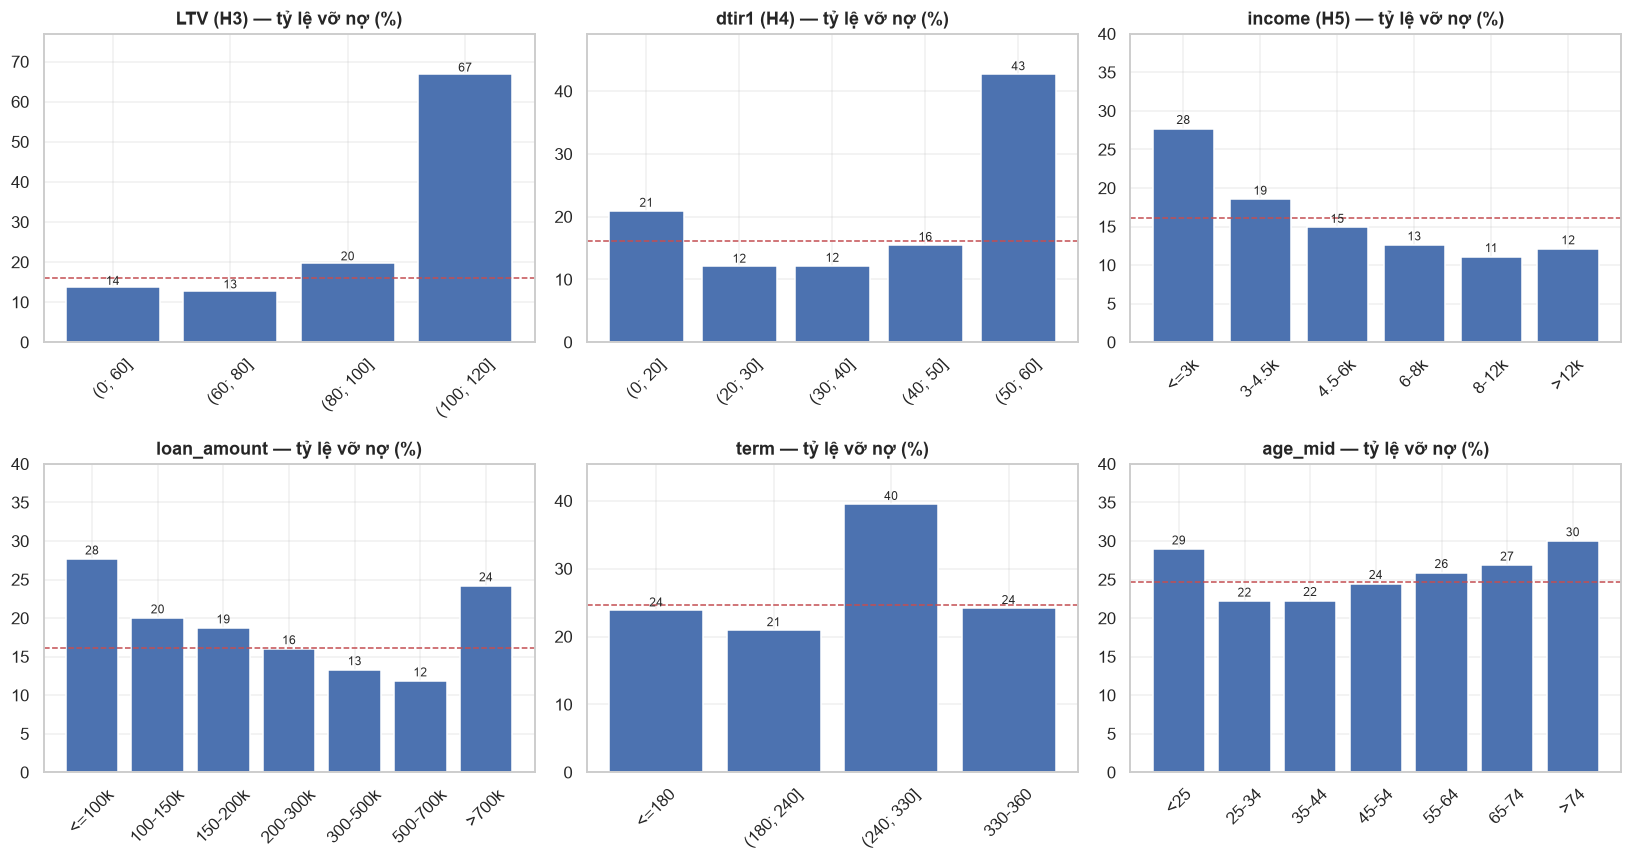

Kruskal-Wallis (tuổi theo nhãn): H = 296,5, p < 0,0001 → tuổi phân biệt nhóm vỡ nợ
Mann-Whitney (LTV): trung vị nhóm vỡ nợ 78,8 so với 73,7 | U = 1.198.921.502, p < 0,0001
Levene (phương sai LTV theo nhãn): W = 139,8, p < 0,0001


In [21]:
BANDS = {
    "LTV (H3)": dict(bins=[0, 60, 80, 100, 120, 900],
                     labels=["(0; 60]", "(60; 80]", "(80; 100]", "(100; 120]", ">120"]),
    "dtir1 (H4)": dict(bins=[0, 20, 30, 40, 50, 60, 1000],
                       labels=["(0; 20]", "(20; 30]", "(30; 40]", "(40; 50]", "(50; 60]", ">60"]),
    "income (H5)": dict(bins=[0, 3000, 4500, 6000, 8000, 12000, 1e9],
                        labels=["<=3k", "3-4.5k", "4.5-6k", "6-8k", "8-12k", ">12k"]),
    "loan_amount": dict(bins=[0, 1e5, 1.5e5, 2e5, 3e5, 5e5, 7e5, 1e9],
                        labels=["<=100k", "100-150k", "150-200k", "200-300k",
                                "300-500k", "500-700k", ">700k"]),
    "term": dict(bins=[0, 180, 240, 330, 361], labels=["<=180", "(180; 240]", "(240; 330]", "330-360"]),
    "age_mid": dict(bins=[0, 25, 35, 45, 55, 65, 75, 200],
                    labels=["<25", "25-34", "35-44", "45-54", "55-64", "65-74", ">74"]),
}
frames = {"LTV (H3)": arena, "dtir1 (H4)": arena, "income (H5)": arena,
          "loan_amount": arena, "term": mfc, "age_mid": mfc}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (name, spec) in zip(axes.ravel(), BANDS.items()):
    col = name.split(" (")[0]
    t = band_rate(frames[name], col, spec["bins"], spec["labels"])["Tỷ lệ vỡ nợ (%)"]
    bars = ax.bar([str(i) for i in t.index], t.values, color="#4C72B0")
    ax.axhline(100 * frames[name][TARGET].mean(), color="#C44E52", ls="--", lw=1)
    for b, val in zip(bars, t.values):
        ax.text(b.get_x() + b.get_width() / 2, val + 0.6, vn(val, 0), ha="center", fontsize=8)
    ax.set_title(f"{name} — tỷ lệ vỡ nợ (%)")
    ax.tick_params(axis="x", rotation=45); ax.set_ylim(0, max(40, t.values.max() * 1.15))
    display(t.rename("Tỷ lệ vỡ nợ (%)").map(lambda x: vn(x, 2)))
fig.tight_layout(); fig.savefig(f"{FIGDIR}/12_h3_h5_continuous.png"); plt.show()

# ---- Kiểm định phi tham số ----
g_def = mfc.loc[mfc[TARGET] == 1, "age_mid"]; g_nd = mfc.loc[mfc[TARGET] == 0, "age_mid"]
H_age, p_age = stats.kruskal(g_def, g_nd)
a_def = arena.loc[arena[TARGET] == 1, "LTV"]; a_nd = arena.loc[arena[TARGET] == 0, "LTV"]
U_ltv, p_ltv = stats.mannwhitneyu(a_def, a_nd, alternative="two-sided")
lev_ltv, p_lev = stats.levene(a_def, a_nd)
print(f"Kruskal-Wallis (tuổi theo nhãn): H = {vn(H_age, 1)}, {pstr(p_age)} → tuổi phân biệt nhóm vỡ nợ")
print(f"Mann-Whitney (LTV): trung vị nhóm vỡ nợ {vn(a_def.median(), 1)} so với {vn(a_nd.median(), 1)} | "
      f"U = {vn(U_ltv)}, {pstr(p_ltv)}")
print(f"Levene (phương sai LTV theo nhãn): W = {vn(lev_ltv, 1)}, {pstr(p_lev)}")

### Kết quả phân tích H3-H5

* **Tỷ lệ đòn bẩy (LTV):** Trong hành lang `arena`, tỷ lệ vỡ nợ ở mức 13,7% và 12,8% khi LTV $\le 80\%$, tăng lên 19,8% trong khoảng (80%; 100%] và đạt 66,9% tại khoảng (100%; 120%]. Khoảng trên 120% sau winsorize không còn dữ liệu do trần P99 (102,76%); trên tập `arena` gốc trước winsorize, dải (100%; 120%] có tỷ lệ vỡ nợ 62,50% và dải trên 120% có 179 hồ sơ với tỷ lệ vỡ nợ lên tới 99,44% (178 ca). Kiểm định Levene ($p < 0,001$) cho thấy phương sai LTV của nhóm vỡ nợ phân tán rộng hơn.
* **Tỷ lệ nợ trên thu nhập (DTI):** Quan hệ giữa DTI và tỷ lệ vỡ nợ có dạng chữ U: 20,98% ở dải $\le 20\%$, giảm xuống 12,1% ở dải 20% đến 40%, sau đó tăng lên 15,54% ở dải 40% đến 50% và 42,73% ở dải 50% đến 60%.
* **Mức thu nhập:** Tỷ lệ vỡ nợ giảm từ 27,7% ở nhóm thu nhập thấp ($\le 3.000$ USD) xuống 11,1% ở nhóm 8.000 đến 12.000 USD, sau đó giữ ở mức 12,1% với nhóm trên 12.000 USD.
* **Độ tuổi:** Phân phối độ tuổi khác biệt có ý nghĩa thống kê giữa hai nhóm nhãn (Kruskal-Wallis $H \approx 297$). Tỷ lệ vỡ nợ thấp nhất ở nhóm 25-44 tuổi (~22%) và cao hơn ở nhóm dưới 25 tuổi (~29%) cùng nhóm trên 74 tuổi (~30%).

* **Lưu ý về dải LTV (100; 120]:** Tỷ lệ vỡ nợ đạt 66,91% ở dải này một phần do phân vị P99 của LTV là 102,76%, nên kỹ thuật winsorize đã nén 179 hồ sơ `arena` có LTV > 120% (tối đa 263,5%, tỷ lệ vỡ nợ gốc 99,44%) về dải này (trên toàn bộ dữ liệu, đuôi LTV kéo dài tới 7.831%). Nhóm hồ sơ có LTV lệch so với tỷ lệ dư nợ/tài sản trên 1 điểm % (tính trên toàn mẫu) có tỷ lệ vỡ nợ 39,45%, tập trung chủ yếu vào các hồ sơ rủi ro cao.

## 3.5. Kiểm định H6: Cấu trúc sản phẩm và đặc điểm hồ sơ

Đánh giá mức độ liên kết giữa các thuộc tính sản phẩm (phương thức trả gốc một lần, cơ chế khấu hao âm, loại hình hồ sơ, người đồng nộp đơn) với biến mục tiêu thông qua hệ số Cramér's V trên toàn bộ các biến danh mục của `X_clean`.

,Đặc trưng,V,χ²,p
0,lump_sum_payment,"0,1877","5.237,8","< 0,0001"
1,Neg_ammortization,"0,1559","3.610,2","< 0,0001"
2,co-applicant_credit_type,"0,1442","3.092,4","< 0,0001"
3,submission_of_application,"0,1209","2.171,7","< 0,0001"
4,loan_type,"0,0939","1.310,0","< 0,0001"
5,business_or_commercial,"0,0925","1.272,8","< 0,0001"
6,Gender,"0,0838","1.043,6","< 0,0001"
7,loan_limit,"0,0542","427,4","< 0,0001"
8,Region,"0,0506","380,5","< 0,0001"
9,loan_purpose,"0,0402","240,2","< 0,0001"


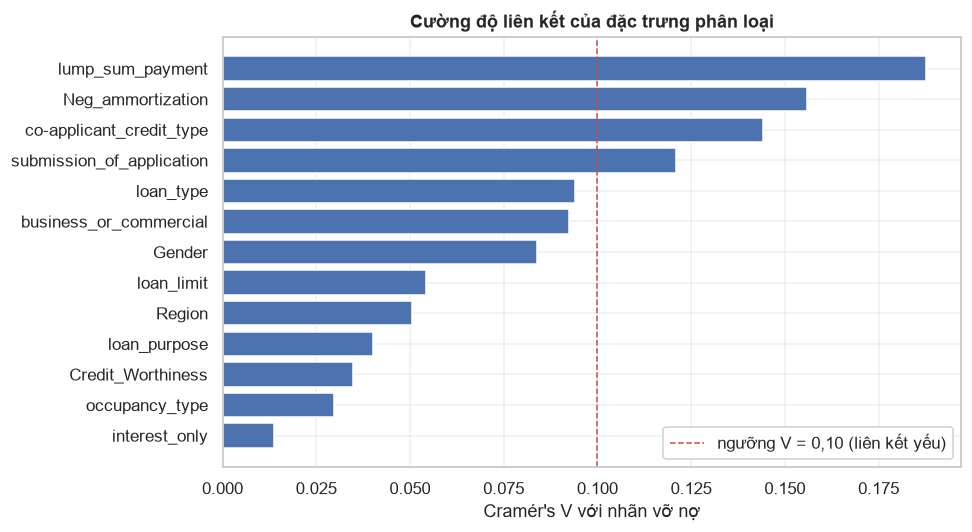


lump_sum_payment


,Số dòng,Tỷ lệ vỡ nợ (%)
lump_sum_payment,,
Trả một lần cuối kỳ,3.384,"77,66"
Trả góp đều,145.286,"23,41"



Neg_ammortization


,Số dòng,Tỷ lệ vỡ nợ (%)
Neg_ammortization,,
Trả dần âm,15.129,"44,60"
Không trả dần âm,133.420,"22,38"



co-applicant_credit_type


,Số dòng,Tỷ lệ vỡ nợ (%)
co-applicant_credit_type,,
Bureau EXP,74.278,"30,87"
Bureau CIB,74.392,"18,43"


In [22]:
sig = pd.DataFrame([
    {"Đặc trưng": c,
     "V": round(cramers_v(mfc[c], mfc[TARGET])[0], 4),
     "χ²": round(cramers_v(mfc[c], mfc[TARGET])[1], 1),
     "p": cramers_v(mfc[c], mfc[TARGET])[2]}
    for c in CAT_CLEAN
]).sort_values("V", ascending=False).reset_index(drop=True)
_sig = sig.copy()
_sig["p"] = _sig["p"].map(pval)
show(_sig, {"V": 4, "χ²": 1})

fig, ax = plt.subplots(figsize=(9, 5))
ss = sig.sort_values("V")
ax.barh(ss["Đặc trưng"], ss["V"], color="#4C72B0")
ax.axvline(0.10, color="#C44E52", ls="--", lw=1, label="ngưỡng V = 0,10 (liên kết yếu)")
ax.set_xlabel("Cramér's V với nhãn vỡ nợ"); ax.set_title("Cường độ liên kết của đặc trưng phân loại")
ax.legend(framealpha=.9); fig.tight_layout(); fig.savefig(f"{FIGDIR}/13_h6_cramers_v.png"); plt.show()

# Bảng tỷ lệ vỡ nợ cho ba tín hiệu mạnh nhất
for col in sig["Đặc trưng"].head(3):
    tab, *_ = cat_signal(col)
    print(f"\n{col}")
    show(tab, {"Số dòng": 0, "Tỷ lệ vỡ nợ (%)": 2})

### Kết quả phân tích H6: Cấu trúc sản phẩm

Hệ số Cramér's V cho thấy các thuộc tính có liên kết mạnh nhất với nhãn gồm:
* Khoản vay trả gốc một lần (`lump_sum_payment`): $V \approx 0,19$, tỷ lệ vỡ nợ đạt ~78%.
* Khoản vay có khấu hao âm (`Neg_ammortization`): $V \approx 0,16$, tỷ lệ vỡ nợ đạt ~45%.
* Kênh thông tin đồng nộp đơn (`co-applicant`): Nhóm EXP có tỷ lệ vỡ nợ 31%, so với 18% của nhóm CIB ($V \approx 0,14$).

Các mối liên kết này phản ánh sự phân bố của các gói sản phẩm trong tập dữ liệu. Trên khía cạnh nghiệp vụ, các khoản vay không áp dụng trả góp định kỳ (trả gốc một lần, khấu hao âm) thường tiềm ẩn áp lực thanh khoản lớn hơn cho người vay vào thời điểm đáo hạn.

## 3.6. Tổng kết kết quả kiểm định giả thuyết

Bảng tổng hợp kết quả kiểm định làm cơ sở cho việc lựa chọn mô hình ở Phần 4:
* H1 và H2 không được dữ liệu ủng hộ: `Credit_Score` không có quan hệ với tỷ lệ vỡ nợ, và không xuất hiện độ dốc bù đắp rủi ro qua lãi suất.
* H3, H4, H5 và H6 ghi nhận các liên kết thống kê rõ nét theo tỷ lệ đòn bẩy LTV, gánh nặng nợ DTI, thu nhập và cấu trúc sản phẩm.

In [23]:
verdict = pd.DataFrame([
    {"Giả thuyết": "H1 — Điểm tín dụng dự báo vỡ nợ", "Giá trị / AUC": f"V = {vn(v1, 4)}, AUC = {vn(auc1, 3)}",
     "Kết luận": "Bác bỏ", "Hành động": "Loại khỏi trọng số; giữ để chứng minh hệ số ≈ 0"},
    {"Giả thuyết": "H2 — Định giá theo rủi ro (lãi suất ~ LTV)",
     "Giá trị / AUC": f"Spearman r = {vn(r_h2, 3)} ({pstr(p_h2)})",
     "Kết luận": "Bác bỏ" if abs(r_h2) < 0.10 else "Chấp nhận",
     "Hành động": "Không có gradient lãi suất trong nhóm quan sát được"},
    {"Giả thuyết": "H3 — Đòn bẩy LTV tăng thì vỡ nợ tăng",
     "Giá trị / AUC": "LTV 12,8% → 19,8% → 66,9% (hành lang)",
     "Kết luận": "Chấp nhận (mô tả)", "Hành động": "Giữ LTV; phân dải đòn bẩy để nhận diện nhóm rủi ro"},
    {"Giả thuyết": "H4 — DTI đơn điệu với vỡ nợ",
     "Giá trị / AUC": "Dạng chữ U: 12% → 43% (hành lang)",
     "Kết luận": "Một phần (phi tuyến)", "Hành động": "Chia dải, không tuyến tính đơn điệu"},
    {"Giả thuyết": "H5 — Thu nhập tăng thì vỡ nợ giảm",
     "Giá trị / AUC": "28% → 11% đơn điệu (hành lang)",
     "Kết luận": "Chấp nhận (mô tả)", "Hành động": "Giữ income (log1p)"},
    {"Giả thuyết": "H6 — Cấu trúc sản phẩm báo hiệu rủi ro",
     "Giá trị / AUC": "V tối đa ≈ 0,19 (lump_sum)",
     "Kết luận": "Chấp nhận (mô tả)", "Hành động": "Giả thuyết cần kiểm chứng"},
])
show(verdict)
print("Kết nối Giai đoạn 4: các liên kết H3–H6 đều bị nhiễu bởi nhóm rò rỉ; "
      "chỉ là mô tả, không phải nhân quả. Không có mô hình PD hợp lệ trên dữ liệu này.")


,Giả thuyết,Giá trị / AUC,Kết luận,Hành động
0,H1 — Điểm tín dụng dự báo vỡ nợ,"V = 0,0066, AUC = 0,503",Bác bỏ,Loại khỏi trọng số; giữ để chứng minh hệ số ≈ 0
1,H2 — Định giá theo rủi ro (lãi suất ~ LTV),"Spearman r = 0,030 (p < 0,0001)",Bác bỏ,Không có gradient lãi suất trong nhóm quan sát...
2,H3 — Đòn bẩy LTV tăng thì vỡ nợ tăng,"LTV 12,8% → 19,8% → 66,9% (hành lang)",Chấp nhận (mô tả),Giữ LTV; phân dải đòn bẩy để nhận diện nhóm rủ...
3,H4 — DTI đơn điệu với vỡ nợ,Dạng chữ U: 12% → 43% (hành lang),Một phần (phi tuyến),"Chia dải, không tuyến tính đơn điệu"
4,H5 — Thu nhập tăng thì vỡ nợ giảm,28% → 11% đơn điệu (hành lang),Chấp nhận (mô tả),Giữ income (log1p)
5,H6 — Cấu trúc sản phẩm báo hiệu rủi ro,"V tối đa ≈ 0,19 (lump_sum)",Chấp nhận (mô tả),Giả thuyết cần kiểm chứng


Kết nối Giai đoạn 4: các liên kết H3–H6 đều bị nhiễu bởi nhóm rò rỉ; chỉ là mô tả, không phải nhân quả. Không có mô hình PD hợp lệ trên dữ liệu này.


# Phần 4. Đánh giá mô hình, tác động danh mục và khuyến nghị

Phần này tập trung vào ba nội dung chính:
1. Định lượng mức độ ảnh hưởng của các thuộc tính rò rỉ đối với hiệu năng mô hình.
2. Đánh giá năng lực phân loại thực tế của mô hình khi chỉ sử dụng tập đặc trưng sạch tại thời điểm thẩm định.
3. Ước lượng mức độ tổn thất danh mục (EAD, LGD, EL) và đề xuất các biện pháp quản trị rủi ro.

## 4.1. Thang đo ROC-AUC đánh giá mức độ rò rỉ

Để đo lường mức độ ảnh hưởng của từng nhóm biến, mô hình Logistic Regression được huấn luyện trên cùng một phép chia train/test nhưng thay đổi dần các tập thuộc tính: từ các trường đặc trưng sạch đến khi bổ sung các cờ khuyết thiếu.

THANG AUC (logit, cùng bộ chia train/test):
  P0  cấu trúc sạch (không cờ thiếu)     AUC = 0,6025
  P1  chỉ cờ thiếu ROI                   AUC = 0,9974
  P2  nhóm 5 cờ thiếu hồ sơ              AUC = 0,9999
  P3  chỉ cờ thiếu spread                AUC = 1,0000
  P4  cờ thiếu + cấu trúc sạch           AUC = 1,0000


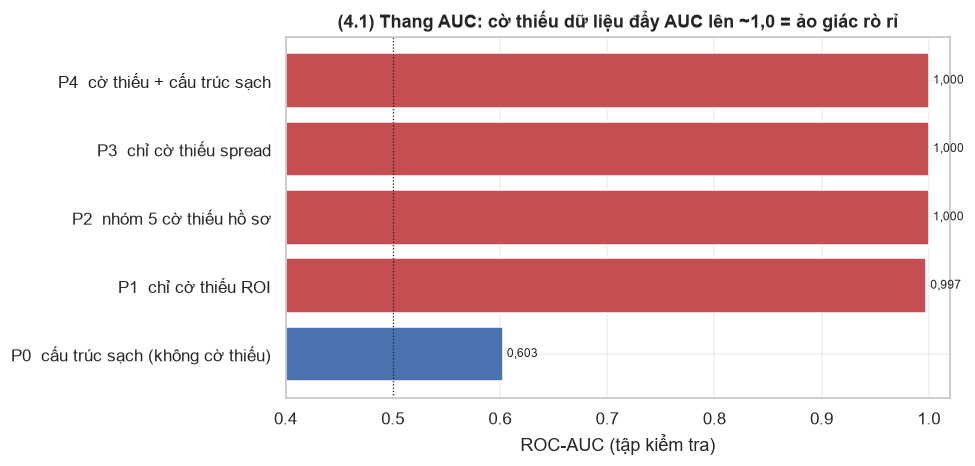

In [24]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             roc_curve)

LR = lambda: LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
HGB = lambda: HistGradientBoostingClassifier(random_state=RANDOM_STATE)

def quick_auc(cols):
    """Logit trên một tập cột thô, cùng phép chia train/test; chỉ đo AUC, không tinh chỉnh."""
    Xtr, Xte, ytr, yte = train_test_split(mfc[cols], y, test_size=TEST_SIZE,
                                          stratify=y, random_state=RANDOM_STATE)
    mdl = Pipeline([("sc", StandardScaler()), ("m", LR())]).fit(Xtr, ytr)
    return roc_auc_score(yte, mdl.predict_proba(Xte)[:, 1])

# Nấc bậc thang: từ "chỉ một cờ" đến "cờ + cấu trúc"
ladder = {
    "P1  chỉ cờ thiếu ROI": quick_auc(["roi_missing"]),
    "P2  nhóm 5 cờ thiếu hồ sơ": quick_auc(MISS_FLAGS),
    "P3  chỉ cờ thiếu spread": quick_auc(["spread_missing"]),
    "P4  cờ thiếu + cấu trúc sạch": quick_auc(NUM_CLEAN + MISS_FLAGS),
    "P0  cấu trúc sạch (không cờ thiếu)": quick_auc(NUM_CLEAN),
}
lad = pd.Series(ladder).sort_index()
print("THANG AUC (logit, cùng bộ chia train/test):")
for k, v in lad.items():
    print(f"  {k:<38} AUC = {vn(v, 4)}")

fig, ax = plt.subplots(figsize=(9, 4.4))
colors = ["#C44E52" if v > 0.9 else "#4C72B0" for v in lad]
ax.barh(list(lad.index), lad.values, color=colors)
ax.axvline(0.5, color="k", lw=.8, ls=":")
ax.set_xlim(0.4, 1.02); ax.set_xlabel("ROC-AUC (tập kiểm tra)")
ax.set_title("(4.1) Thang AUC: cờ thiếu dữ liệu đẩy AUC lên ~1,0 = ảo giác rò rỉ")
for ypos, v in zip(range(len(lad)), lad.values):
    ax.text(v + .004, ypos, vn(v, 3), va="center", fontsize=8)
fig.tight_layout(); fig.savefig(f"{FIGDIR}/14_auc_ladder.png"); plt.show()


### Nhận xét về tác động của rò rỉ dữ liệu

Đưa vào cờ khuyết thiếu `spread_missing` lập tức nâng chỉ số ROC-AUC lên 1,0000 do vị trí khuyết thiếu trùng khớp với toàn bộ các ca vỡ nợ. Tương tự, nhóm cờ thiếu hồ sơ cũng đưa AUC lên mức gần tuyệt đối (0,9999).

Khi loại bỏ toàn bộ cờ thiếu và chỉ dùng 8 biến số cấu trúc khoản vay, ROC-AUC dừng ở mức 0,6025 (nấc P0). Điểm số chỉ nâng lên khoảng 0,73 đến 0,75 khi bổ sung 13 biến phân loại đã chuẩn hóa và áp dụng biến đổi log1p cho nhóm tiền tệ (như thể hiện ở Mô hình A và B tại mục 4.2). Điều này cho thấy điểm số AUC trên 0,90 thường thấy trên bộ dữ liệu này có đóng góp rất lớn từ cơ chế ghi nhận khuyết thiếu.

## 4.2. So sánh hiệu năng các cấu hình mô hình

Phần này đánh giá ba cấu hình mô hình để làm rõ ranh giới thông tin:
* **Mô hình A (Sạch toàn mẫu - Logistic Regression):** Huấn luyện trên `X_clean` gồm 8 biến số và 13 biến phân loại đã loại bỏ các trường rò rỉ trực tiếp.
* **Mô hình A2 (Khai thác giá trị khuyết - HistGradientBoosting):** Huấn luyện trên tập đặc trưng có giữ lại `rate_of_interest` ở dạng NaN, kiểm chứng khả năng cây quyết định tự động tách rò rỉ để đạt AUC = 1,0.
* **Mô hình B (Hành lang so sánh - Logistic Regression):** Huấn luyện trên tập con `arena` gồm các hồ sơ có đầy đủ 4 trường thông tin định giá tài sản sau khi phục hồi bằng đồng nhất thức.

KIỂM CHỨNG: AUC(A, Status) = 0,7456 | AUC(A, LEAK_MASK) = 0,7456


,Số hồ sơ,Xác suất trung bình
Nhóm,,
A,3.819,"0,462"
B,47,"0,680"
D,28.008,"0,205"
E,5.294,"0,317"


SO SÁNH BA TẦNG:


,AUC,AP,Brier,Số quan sát test,Tỷ lệ vỡ nợ nền (%)
A — sạch toàn mẫu (logit),"0,7456","0,5450","0,1533",37.168,"24,64"
A2 — HGB đọc NaN của lãi suất,"1,0000","1,0000","0,0003",37.168,"24,64"
B — hành lang (logit),"0,7293","0,3964","0,1183",31.023,"16,10"


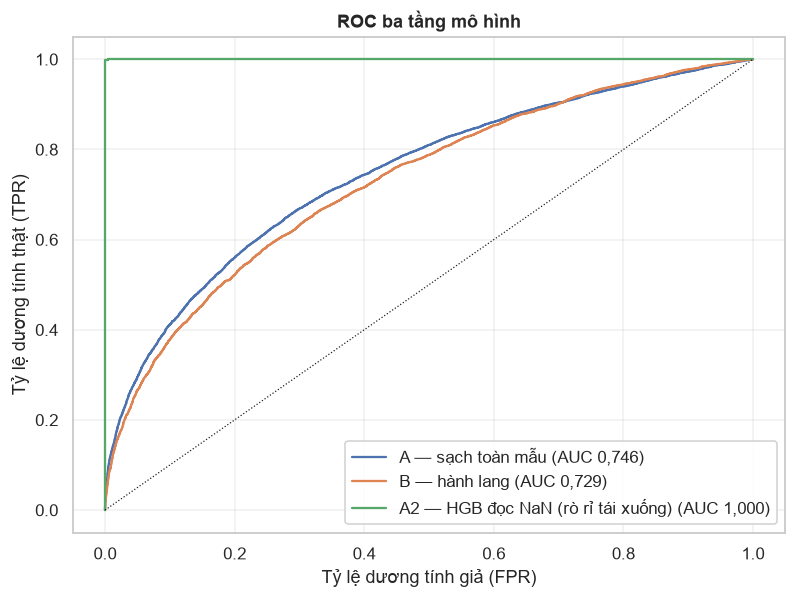

In [25]:
def score_pipe(mdl, Xtr, ytr, Xte, yte):
    mdl.fit(Xtr, ytr); p = mdl.predict_proba(Xte)[:, 1]
    return p, dict(AUC=roc_auc_score(yte, p), AP=average_precision_score(yte, p),
                   Brier=brier_score_loss(yte, p))

# Tầng 2: sạch toàn mẫu (logit qua pre_clean)
mA = Pipeline([("pre", clone(pre_clean)), ("m", LR())])
pA, mA = score_pipe(mA, Xc_tr, yc_tr, Xc_te, yc_te)

# Kiểm chứng: mô hình A có vượt qua phép phân tách nhóm rò rỉ?
print(f"KIỂM CHỨNG: AUC(A, Status) = {vn(roc_auc_score(yc_te, pA), 4)} | "
      f"AUC(A, LEAK_MASK) = {vn(roc_auc_score(LEAK_MASK.loc[yc_te.index].astype(int), pA), 4)}")
grp_te = pd.Series("D", index=yc_te.index)
grp_te[NULL_CLUSTER.loc[yc_te.index]] = "A"
grp_te[EQ_OUT.loc[yc_te.index]] = "B"
grp_te[ROI_ONLY.loc[yc_te.index]] = "E"
show(pd.DataFrame({"Xác suất": pA, "Nhóm": grp_te}).groupby("Nhóm")["Xác suất"]
     .agg(**{"Số hồ sơ": "size", "Xác suất trung bình": "mean"}),
     {"Số hồ sơ": 0, "Xác suất trung bình": 3})

# Tầng 2b: sạch toàn mẫu nhưng bằng HGB để HGB tự đọc NaN của lãi suất → rò rỉ tái xuống
Xnan = mfc[NUM_CLEAN + ["rate_of_interest"]].copy()
Xn_tr, Xn_te, yn_tr, yn_te = train_test_split(Xnan, y, test_size=TEST_SIZE,
                                              stratify=y, random_state=RANDOM_STATE)
pA2, mA2 = score_pipe(HGB(), Xn_tr, yn_tr, Xn_te, yn_te)

# Tầng 3: hành lang arena (logit sạch, dùng CÙNG biến đổi log1p như tầng 2)
Xb = log1p_money(arena[NUM_CLEAN + CAT_CLEAN].copy())
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, arena[TARGET].astype(int),
        test_size=TEST_SIZE, stratify=arena[TARGET], random_state=RANDOM_STATE)
mB = Pipeline([("pre", clone(pre_clean)), ("m", LR())])
pB, mB_metrics = score_pipe(mB, Xb_tr, yb_tr, Xb_te, yb_te)

res = pd.DataFrame({"A — sạch toàn mẫu (logit)": mA,
                    "A2 — HGB đọc NaN của lãi suất": mA2,
                    "B — hành lang (logit)": mB_metrics}).T.round(4)
res["Số quan sát test"] = [len(yc_te), len(yn_te), len(yb_te)]
res["Tỷ lệ vỡ nợ nền (%)"] = [100*yc_te.mean(), 100*yn_te.mean(), 100*yb_te.mean()]
print("SO SÁNH BA TẦNG:")
show(res, {"AUC": 4, "AP": 4, "Brier": 4, "Số quan sát test": 0,
              "Tỷ lệ vỡ nợ nền (%)": 2})

# ROC so sánh
fig, ax = plt.subplots(figsize=(7.4, 5.6))
for (p, yte, lbl) in [(pA, yc_te, "A — sạch toàn mẫu"), (pB, yb_te, "B — hành lang"),
                      (pA2, yn_te, "A2 — HGB đọc NaN (rò rỉ tái xuống)")]:
    fpr, tpr, _ = roc_curve(yte, p)
    ax.plot(fpr, tpr, label=f"{lbl} (AUC {vn(roc_auc_score(yte, p), 3)})")
ax.plot([0,1],[0,1], "k:", lw=.8)
ax.set_xlabel("Tỷ lệ dương tính giả (FPR)"); ax.set_ylabel("Tỷ lệ dương tính thật (TPR)")
ax.set_title("ROC ba tầng mô hình")
ax.legend(loc="lower right", framealpha=.9); fig.tight_layout()
fig.savefig(f"{FIGDIR}/15_roc_three_tier.png"); plt.show()

### Đánh giá kết quả mô hình

Mô hình A đạt AUC 0,7456 và Average Precision (AP) 0,5450 trên toàn mẫu. Mô hình B trên hành lang `arena` đạt AUC 0,7293 và AP 0,3964. Điểm AP của mô hình B thấp hơn chủ yếu do tỷ lệ vỡ nợ nền trong hành lang `arena` chỉ còn 16,10% (so với 24,64% trên toàn mẫu), vì điều kiện đủ dữ liệu định giá đã tự động loại bớt các hồ sơ rủi ro cao. Tương tự, chỉ số Brier score của mô hình B (0,1183) thấp hơn mô hình A (0,1533) một phần do tỷ lệ vỡ nợ nền thấp hơn (mô hình dự đoán hằng số theo tỷ lệ nền p(1-p) trên arena cho Brier 0,1351 so với 0,1857 toàn mẫu). Do đó, thang đo ROC-AUC (vốn không phụ thuộc tỷ lệ nền) cho thấy chênh lệch nhỏ về năng lực phân loại giữa hai mô hình (chênh 0,0163).

Kiểm tra đối chiếu cho thấy `AUC(A, Status)` bằng đúng `AUC(A, LEAK_MASK)` = 0,7456. Xác suất dự báo trung bình của mô hình A phân bổ theo từng nhóm lần lượt là: nhóm A: 0,462; nhóm B: 0,680; nhóm E: 0,317; nhóm D: 0,205. Điểm số của mô hình này phản ánh khả năng phân tách giữa nhóm hồ sơ khuyết thiếu và nhóm đầy đủ thông tin hơn là quan hệ tín dụng độc lập.

Khi sử dụng thuật toán hỗ trợ giá trị khuyết tự nhiên như HistGradientBoosting trên dữ liệu còn giữ `rate_of_interest` (mô hình A2), mô hình đạt AUC tuyệt đối 1,0000 do tự động khai thác vị trí NaN.

## 4.3. Phân tích ngưỡng cắt và hệ số Lift

Khảo sát hệ số Lift theo thập phân vị (decile), tỷ lệ phát hiện (capture rate) và ma trận nhầm lẫn của Mô hình A nhằm đánh giá khả năng phân loại hồ sơ rủi ro cao.

,Số dòng,Số ca vỡ nợ,Tỷ lệ vỡ nợ (%),Tỷ lệ bắt được lũy kế (%),Tỷ trọng vỡ nợ (%)
decile,,,,,
D1,3.717,310,"8,34","100,0","3,4"
D2,3.717,369,"9,93","96,6","4,0"
D3,3.717,405,"10,90","92,6","4,4"
D4,3.716,508,"13,67","88,2","5,5"
D5,3.717,644,"17,33","82,6","7,0"
D6,3.717,728,"19,59","75,6","7,9"
D7,3.716,942,"25,35","67,6","10,3"
D8,3.717,1.184,"31,85","57,4","12,9"
D9,3.717,1.556,"41,86","44,4","17,0"


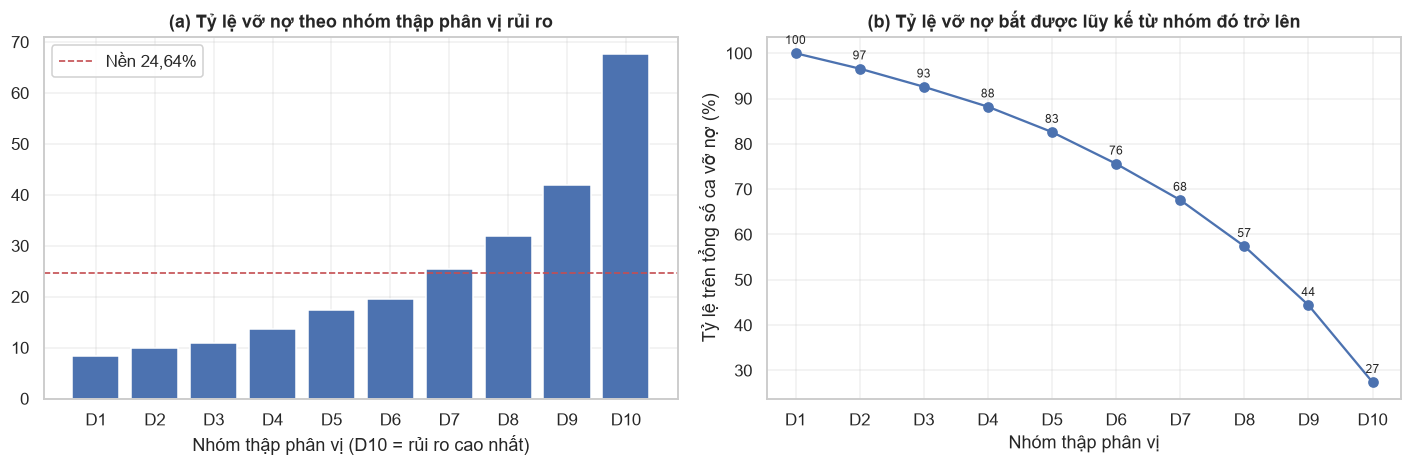

Ngưỡng top-20% (p ≥ 0,372) → cảnh báo 20,0% hồ sơ
  Độ chính xác của cảnh báo 0,547 | Tỷ lệ bắt được 0,444 | F1 0,491
  Nhầm lẫn: TN=24.644  FP=3.364  FN=5.090  TP=4.070
  Số ca vỡ nợ bỏ sót 5.090/9.160 (55,6% tổng số ca vỡ nợ)


In [26]:
from sklearn.metrics import confusion_matrix

# (i) Lift theo nhóm thập phân vị của xác suất dự đoán (tăng dần: D1 thấp nhất → D10 cao nhất)
op = pd.DataFrame({"y": np.asarray(yc_te), "p": pA})
op["decile"] = pd.qcut(op["p"], 10, labels=[f"D{i}" for i in range(1, 11)],
                       duplicates="drop")
grp = op.groupby("decile", observed=True)["y"]
lif = grp.agg(**{"Số dòng": "size", "Số ca vỡ nợ": "sum", "Tỷ lệ vỡ nợ (%)": "mean"})
lif["Tỷ lệ vỡ nợ (%)"] = (100 * lif["Tỷ lệ vỡ nợ (%)"]).round(2)
# cum_capture = % tổng số ca vỡ nợ nằm trong các nhóm thập phân vị từ đó trở lên (đọc từ phải sang trái)
lif["Tỷ lệ bắt được lũy kế (%)"] = (100 * lif["Số ca vỡ nợ"][::-1].cumsum()[::-1]
                        / op["y"].sum()).round(1)
lif["Tỷ trọng vỡ nợ (%)"] = (100 * lif["Số ca vỡ nợ"] / op["y"].sum()).round(1)
show(lif, {"Số dòng": 0, "Số ca vỡ nợ": 0, "Tỷ lệ vỡ nợ (%)": 2,
              "Tỷ lệ bắt được lũy kế (%)": 1, "Tỷ trọng vỡ nợ (%)": 1})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
idx = [str(i) for i in lif.index]
axes[0].bar(idx, lif["Tỷ lệ vỡ nợ (%)"], color="#4C72B0")
axes[0].axhline(100 * op["y"].mean(), color="#C44E52", ls="--", lw=1.1,
                label=f"Nền {vn(100 * op['y'].mean(), 2)}%")
axes[0].set_title("(a) Tỷ lệ vỡ nợ theo nhóm thập phân vị rủi ro")
axes[0].set_xlabel("Nhóm thập phân vị (D10 = rủi ro cao nhất)"); axes[0].legend(framealpha=.9)
axes[1].plot(idx, lif["Tỷ lệ bắt được lũy kế (%)"], marker="o", color="#4C72B0")
axes[1].set_title("(b) Tỷ lệ vỡ nợ bắt được lũy kế từ nhóm đó trở lên")
axes[1].set_xlabel("Nhóm thập phân vị"); axes[1].set_ylabel("Tỷ lệ trên tổng số ca vỡ nợ (%)"); axes[1].grid(alpha=.3)
for xi, v in zip(idx, lif["Tỷ lệ bắt được lũy kế (%)"]):
    axes[1].annotate(vn(v, 0), (xi, v), textcoords="offset points", xytext=(0, 6),
                     ha="center", fontsize=8)
fig.tight_layout(); fig.savefig(f"{FIGDIR}/16_lift_decile.png"); plt.show()

# (ii) Ngưỡng vận hành: chỉ kiểm tra lại 20% hồ sơ có điểm rủi ro cao nhất
thr_top20 = float(op["p"].quantile(0.80))
pred20 = (op["p"] >= thr_top20).astype(int)
tn, fp, fn, tp = confusion_matrix(op["y"], pred20).ravel()
print(f"Ngưỡng top-20% (p ≥ {vn(thr_top20, 3)}) → cảnh báo {vn(100 * pred20.mean(), 1)}% hồ sơ")
print(f"  Độ chính xác của cảnh báo {vn(tp / (tp + fp), 3)} | Tỷ lệ bắt được {vn(tp / (tp + fn), 3)} | "
      f"F1 {vn(2 * tp / (2 * tp + fp + fn), 3)}")
print(f"  Nhầm lẫn: TN={vn(tn)}  FP={vn(fp)}  FN={vn(fn)}  TP={vn(tp)}")
print(f"  Số ca vỡ nợ bỏ sót {vn(fn)}/{vn(int(op['y'].sum()))} "
      f"({vn(100 * fn / op['y'].sum(), 1)}% tổng số ca vỡ nợ)")

### Nhận xét về chỉ số phân tầng rủi ro

Nhóm 10% hồ sơ có điểm rủi ro cao nhất (D10) ghi nhận tỷ lệ vỡ nợ 67,6%, cao gấp 2,7 lần tỷ lệ nền (24,6%). Hai nhóm cao nhất (D9 và D10) bao phủ 44,4% tổng số ca vỡ nợ. Tại ngưỡng này, độ chính xác (precision) đạt 0,547 và tỷ lệ bỏ sót (false negative) là 55,6% (5.090 trên 9.160 ca trong tập test).

Sự tập trung này phản ánh việc mô hình nhận diện nhóm hồ sơ thuộc phân khúc khuyết thiếu. Khi triển khai thực tế, mô hình cần được tái thẩm định trên nguồn dữ liệu ghi nhận đầy đủ tại thời điểm duyệt vay.

## 4.4. Ước lượng tổn thất danh mục: EAD, LGD và Tổn thất kỳ vọng (EL)

Tính toán các chỉ số tổn thất tín dụng trên dữ liệu gốc chưa winsorize để đảm bảo giá trị tiền tệ thực tế:
* Phơi nhiễm khi vỡ nợ (EAD): Sử dụng giá trị giải ngân ban đầu `loan_amount` làm đại diện cho dư nợ tại thời điểm vỡ nợ.
* Tỷ lệ tổn thất khi vỡ nợ (LGD): Ước lượng dựa trên giả định thanh lý tài sản bảo đảm với mức chiết khấu cưỡng chế bán (haircut) 10%, tức giá trị thu hồi đạt $0,9 \times property\_value$.
* Tổn thất kỳ vọng (EL): $EL = EAD \times LGD$.

Lưu ý: LGD chỉ tính toán được trên 21.543 khoản vỡ nợ có ghi nhận `property_value`. Khoảng 15.096 khoản vỡ nợ bị khuyết giá trị định giá tài sản không thể xác định giá trị thu hồi trực tiếp (xem hạn chế tại mục 4.5).

Tổng phơi nhiễm danh mục      : 49,23 tỷ USD
Phơi nhiễm tại thời điểm vỡ nợ (EAD): 11,70 tỷ USD = 23,8% danh mục
Vỡ nợ đo được LGD: 21.543/36.639 hồ sơ (58,8%), dư nợ 6,72 tỷ USD trong 11,70 tỷ USD EAD
LGD trung bình 2,20% | trung vị 0,00% | tỷ lệ hồ sơ LGD = 0 (thu đủ nợ): 73,4%
Khoản lỗ kỳ vọng EL (giả định chiết khấu 90%): 127,9 triệu USD (≥ 1,09% EAD toàn danh mục, cận dưới đo được; bằng 1,90% EAD nhóm có dữ liệu)
Nhóm dư nợ vượt giá trị tài sản: 1.171 hồ sơ (5,4% số đo được LGD), LGD trung bình 18,43%, tổn thất 56,1 triệu USD = 43,9% tổng EL


,Số hồ sơ,LGD trung bình (%),Tổn thất (triệu USD)
ltv_goc,,,
(0; 60],4.534,"0,00","0,0"
(60; 80],6.456,"0,00","0,0"
(80; 90],4.822,"0,00","0,0"
(90; 100],4.560,"5,67","71,7"
(100; 120],985,"15,62","44,8"
>120,186,"33,29","11,3"


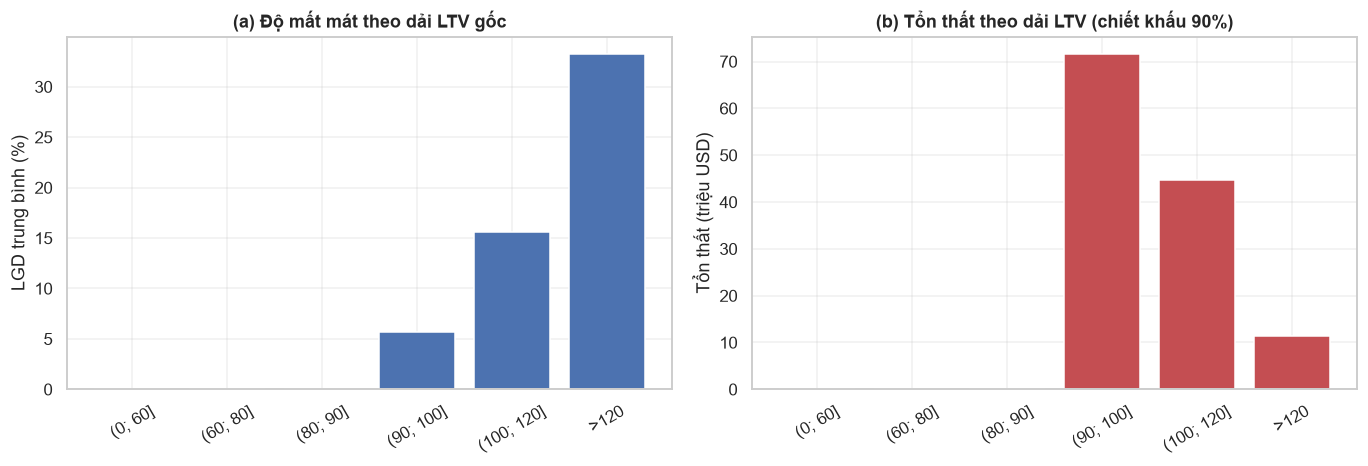

In [27]:
HAIRCUT = 0.90          # giá bán thanh lý ép (forced-sale) khi thu tài sản đảm bảo
book = raw["loan_amount"].sum()
d = raw[raw[TARGET] == 1]
ead = d["loan_amount"].sum()
print(f"Tổng phơi nhiễm danh mục      : {vn(book / 1e9, 2)} tỷ USD")
print(f"Phơi nhiễm tại thời điểm vỡ nợ (EAD): {vn(ead / 1e9, 2)} tỷ USD "
      f"= {vn(100 * ead / book, 1)}% danh mục")

d_pv = d[d["property_value"].notna() & (d["property_value"] > 0)].copy()
d_pv["recovery"] = np.minimum(d_pv["loan_amount"], d_pv["property_value"] * HAIRCUT)
d_pv["lgd"] = ((d_pv["loan_amount"] - d_pv["recovery"]) / d_pv["loan_amount"]).clip(0, 1)
d_pv["ltv_goc"] = d_pv["loan_amount"] / d_pv["property_value"] * 100
el = (d_pv["loan_amount"] - d_pv["recovery"]).clip(lower=0).sum()

print(f"Vỡ nợ đo được LGD: {vn(len(d_pv))}/{vn(len(d))} hồ sơ "
      f"({vn(100 * len(d_pv) / len(d), 1)}%), dư nợ {vn(d_pv['loan_amount'].sum() / 1e9, 2)} tỷ USD "
      f"trong {vn(ead / 1e9, 2)} tỷ USD EAD")
print(f"LGD trung bình {vn(100 * d_pv['lgd'].mean(), 2)}% | trung vị {vn(100 * d_pv['lgd'].median(), 2)}% | "
      f"tỷ lệ hồ sơ LGD = 0 (thu đủ nợ): {vn(100 * (d_pv['lgd'] == 0).mean(), 1)}%")
ead_obs = d_pv["loan_amount"].sum()
print(f"Khoản lỗ kỳ vọng EL (giả định chiết khấu {HAIRCUT:.0%}): {vn(el / 1e6, 1)} triệu USD "
      f"(≥ {vn(100 * el / ead, 2)}% EAD toàn danh mục, cận dưới đo được; "
      f"bằng {vn(100 * el / ead_obs, 2)}% EAD nhóm có dữ liệu)")

under = d_pv[d_pv["ltv_goc"] > 100]
under_loss = (under["loan_amount"] - under["recovery"]).clip(lower=0).sum()
print(f"Nhóm dư nợ vượt giá trị tài sản: {vn(len(under))} hồ sơ "
      f"({vn(100 * len(under) / len(d_pv), 1)}% số đo được LGD), "
      f"LGD trung bình {vn(100 * under['lgd'].mean(), 2)}%, "
      f"tổn thất {vn(under_loss / 1e6, 1)} triệu USD = {vn(100 * under_loss / el, 1)}% tổng EL")

lgd_band = (d_pv.groupby(pd.cut(d_pv["ltv_goc"], [0, 60, 80, 90, 100, 120, np.inf],
            labels=["(0; 60]", "(60; 80]", "(80; 90]", "(90; 100]", "(100; 120]", ">120"],
            include_lowest=True), observed=True)
            .apply(lambda g: pd.Series({
                "Số hồ sơ": len(g),
                "LGD trung bình (%)": round(100 * g["lgd"].mean(), 2),
                "Tổn thất (triệu USD)": round((g["loan_amount"] - g["recovery"])
                                            .clip(lower=0).sum() / 1e6, 1)})))
show(lgd_band, {"Số hồ sơ": 0, "LGD trung bình (%)": 2, "Tổn thất (triệu USD)": 1})

fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.4))
idx = [str(i) for i in lgd_band.index]
axes[0].bar(idx, lgd_band["LGD trung bình (%)"], color="#4C72B0")
axes[0].set_ylabel("LGD trung bình (%)"); axes[0].set_title("(a) Độ mất mát theo dải LTV gốc")
axes[1].bar(idx, lgd_band["Tổn thất (triệu USD)"], color="#C44E52")
axes[1].set_ylabel("Tổn thất (triệu USD)"); axes[1].set_title(f"(b) Tổn thất theo dải LTV (chiết khấu {HAIRCUT:.0%})")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
fig.tight_layout(); fig.savefig(f"{FIGDIR}/17_lgd_severity.png"); plt.show()

### Nhận xét về tổn thất danh mục

* **Điểm phát sinh tổn thất:** Với giả định chiết khấu thanh lý 10% (`recovery = 0,9 * property_value`), tổn thất vốn phát sinh khi LTV vượt 90%. Nhóm hồ sơ có LTV $\le 90\%$ có giá trị tài sản đủ bù đắp dư nợ theo giả định này.
* **Cơ cấu tổn thất theo LTV:** Khoảng LTV từ 90% đến 100% có LGD trung bình 5,67% và đóng góp 71,7 triệu USD (chiếm 56,1% tổng tổn thất kỳ vọng quan sát được). Nhóm LTV > 100% có mức độ tổn thất bình quân cao hơn rõ rệt (LGD 18,4%), đóng góp 56,1 triệu USD (43,9% tổng EL).
* **Quy mô danh mục chưa định giá:** 15.096 trên 36.639 khoản vỡ nợ (41,2%) thiếu thông tin tài sản bảo đảm, do đó tổng mức tổn thất 127,9 triệu USD chỉ là cận dưới đo lường được (tương ứng $\ge 1,09\%$ tổng EAD toàn danh mục; nếu tính riêng trên nhóm có dữ liệu định giá thì tỷ lệ tổn thất là 1,90% EAD).

## 4.5. Tổng kết, khuyến nghị và định hướng

### Ba phát hiện trọng tâm

* **Phát hiện 1 (Rò rỉ dữ liệu qua cơ chế khuyết thiếu):** Số lượng dòng khuyết `Interest_rate_spread` bằng đúng số ca vỡ nợ (36.639 dòng), và `rate_of_interest` khuyết ở 99,45% ca vỡ nợ. Do đó, các mô hình học máy thông thường dễ đạt điểm số AUC xấp xỉ 1,000 do đọc được cơ chế thu thập dữ liệu thay vì nhận diện hành vi tín dụng.
* **Phát hiện 2 (Giới hạn tín hiệu dự báo độc lập):** Điểm tín dụng không có năng lực phân loại đối với nhãn vỡ nợ (AUC đơn biến xấp xỉ 0,50; Cramér's V xấp xỉ 0,007). Các tương quan ghi nhận với LTV cao hoặc loại hình trả nợ đều tập trung tại nhóm hồ sơ khuyết thiếu, cần được thu thập lại để kiểm chứng trên dữ liệu chuẩn.
* **Phát hiện 3 (Phân bổ tổn thất kỳ vọng):** Dưới giả định chiết khấu thanh lý tài sản 10%, tổn thất vốn phát sinh từ ngưỡng LTV > 90%. Khoảng LTV từ 90% đến 100% chiếm 56,1% tổng tổn thất kỳ vọng đo lường được (71,7 triệu USD), trong khi nhóm LTV > 100% chiếm 43,9% (56,1 triệu USD) với LGD trung bình 18,4%.

### Khuyến nghị thực hành

| STT | Khuyến nghị | Căn cứ từ phân tích | Tiêu chí đánh giá thành công |
|---|---|---|---|
| 1 | Không sử dụng các cờ khuyết thiếu và các trường lãi suất bị rò rỉ làm đặc trưng dự báo. Lưu ý rằng mô hình A hiện tại vẫn sử dụng các trường định giá (property_value, LTV, dtir1, income) đã qua điền khuyết toàn mẫu, do đó AUC 0,746 vẫn mang dấu ấn của việc phân tách nhóm rò rỉ | Thang AUC: cờ thiếu đơn lẻ cho AUC xấp xỉ 1,000 | Sau khi chuẩn hóa dữ liệu: AUC kỳ vọng đạt 0,65-0,80 |
| 2 | Thu thập lại dữ liệu định giá tại thời điểm giải ngân (origination-time snapshot) thay vì cập nhật sau khi khoản vay chuyển sang trạng thái vỡ nợ | Hiện tượng thiếu dữ liệu trùng khớp với nhãn | Tỷ lệ hồ sơ có đủ thông tin lãi suất và định giá ở cả hai nhóm nhãn |
| 3 | Không sử dụng mô hình hiện tại để phê duyệt tín dụng thực tế, chỉ dùng để kiểm toán dữ liệu | Điểm số AUC 0,746 phản ánh việc phân tách nhóm rò rỉ | Quy trình phê duyệt không dựa trên mô hình bị rò rỉ này |
| 4 | Cân nhắc trần LTV 90% theo giả định chiết khấu thanh lý tài sản | 56,1% tổn thất kỳ vọng phát sinh trong khoảng LTV từ 90% đến 100% | Tỷ lệ tổn thất danh mục giảm khi áp dụng trần LTV mới |
| 5 | Áp dụng điền khuyết bằng trung vị kết hợp cờ báo thiếu cho các trường kỹ thuật; không áp dụng phương pháp điền trung bình | Thực nghiệm mục 2.5: Điền trung bình làm lệch vị trí phân phối thu nhập khoảng 22% (1.256 USD/tháng) | Sai số hoàn tác trên tập kiểm tra độc lập duy trì ổn định |
| 6 | Minh bạch hóa danh mục đặc trưng và thang đo AUC trong quy trình phát triển mô hình | Mục 2.7 và 4.1 | Quy trình có khả năng kiểm toán độc lập và tái lập hoàn toàn |

### Hạn chế của bộ dữ liệu

* **Thiếu chiều thời gian:** Không ghi nhận ngày giải ngân hoặc lịch sử thanh toán chi tiết, do đó không thể kiểm định theo mẫu hình thời gian (out-of-time validation) hoặc xây dựng ma trận chuyển dịch nhóm nợ.
* **Không quan sát được dòng tiền xử lý nợ thực tế:** Chỉ số LGD được ước lượng từ giá trị tài sản bảo đảm và giả định mức chiết khấu thanh lý (haircut), chưa phản ánh chi phí thu hồi nợ thực tế.
* **41,2% ca vỡ nợ thiếu thông tin tài sản:** 15.096 trên 36.639 hồ sơ vỡ nợ không có giá trị tài sản bảo đảm, do đó tổng mức tổn thất đo lường được là cận dưới ($\ge 127,9$ triệu USD).
* **Đặc tính phân phối của `Credit_Score`:** Điểm tín dụng có độ phân tán lớn nhưng không có tương quan với nhãn, cần đối chiếu lại quy trình thu thập với đơn vị cung cấp dữ liệu.
* **Biến danh mục có độ biến thiên thấp:** Một số trường gần như là hằng số (`Security_Type`, `Secured_by`, `construction_type`) làm giảm hiệu quả kiểm định Chi-square.
* **Giới hạn của mô hình trên nhóm đầy đủ thông tin:** Phân khúc D (112.030 dòng) không có ca vỡ nợ nào, do đó hiệu năng phân loại hiện tại chủ yếu đo lường việc phân tách giữa các nhóm hồ sơ khác nhau về mức độ đầy đủ dữ liệu.
* **Ảnh hưởng của bước làm sạch toàn mẫu:** Giá trị trung vị và phân vị P1-P99 được tính toán trên toàn bộ dữ liệu trước khi phân chia train/test.

### Hướng phát triển tiếp theo

1. **Chuẩn hóa nhãn mục tiêu:** Xác định rõ tiêu chí vỡ nợ theo số ngày quá hạn (ví dụ: 90+ DPD) tại mốc thời gian cụ thể và tái lập dữ liệu chỉ gồm các trường có trước mốc đó.
2. **Xây dựng mô hình ba cấu phần Basel (PD, LGD, EAD):** Ước lượng xác suất vỡ nợ (PD) trên tập dữ liệu đã chuẩn hóa, kết hợp mô hình hóa LGD theo từng phân khúc tài sản và địa bàn.
3. **Mô hình phân tích thời gian sống (Survival Analysis):** Khai thác chiều thời gian trả nợ để dự báo thời điểm phát sinh rủi ro thay vì bài toán phân loại nhị phân đơn thuần.
4. **Kiểm toán tính công bằng (Fairness Audit):** Đánh giá tác động của các biến nhân khẩu học (`Gender`, `Region`) trước khi đưa vào hệ thống chấm điểm chính thức.
5. **Theo dõi độ ổn định đặc trưng (PSI/CSI):** Giám sát sự dịch chuyển của dữ liệu theo thời gian để phát hiện sớm các hiện tượng rò rỉ mới.

### Kết luận

Giá trị then chốt của báo cáo là nhận diện và cô lập hiện tượng rò rỉ dữ liệu bắt nguồn từ cơ chế ghi nhận hồ sơ thế chấp năm 2019. Kết quả phân tích khẳng định tập dữ liệu này chưa đủ điều kiện để xây dựng một mô hình chấm điểm tín dụng thương mại do các ca vỡ nợ gắn liền với tình trạng khuyết thiếu thông tin. Các kết quả giá trị nhất của nghiên cứu bao gồm việc kiểm toán cơ chế rò rỉ, phân tích cấu trúc rủi ro theo sản phẩm và ước lượng khung tổn thất danh mục theo các giả định quản trị rủi ro rõ ràng.